# 03 Python项目实战之AI应用

本章根据桌面讲义《第3章-Python项目实战之AI应用》整理，围绕一个完整项目：**用 Python、DeepSeek API 和 Streamlit 开发“AI 智能伴侣”**。

前两章解决了“Python 怎么写”；这一章要把变量、列表、字典、条件、循环、函数、模块和异常处理放到真正的应用里。用户在网页上输入一句话，Python 程序把它组织成请求发给模型，再把回答呈现在页面上；继续聊天时携带历史；关闭应用之前把会话写入文件，下次还能加载。

学习内容按照讲义分为三部分：

| 部分 | 内容 | 要解决的问题 |
| --- | --- | --- |
| AI 应用基础 | AI、大模型、部署方案、网络、HTTP、API 测试、SDK、提示词 | 程序如何与大模型通信 |
| AI 应用实战 | Streamlit、聊天交互、会话记忆、性格设置、会话管理 | 如何做出可交互、能保存历史的应用 |
| 知识扩展 | 相对路径、绝对路径、文件打开模式 | 文件到底存在哪里，读写方式有何区别 |

**阅读说明：**讲义中的知识、示例和复习问题合并到对应主题，重复动画页只写一次。实战部分有些 PPT 只给界面和需求，没有完整源代码；本文会明确标注“补充：参考实现”，把完成课程项目所必需的代码补齐。版本差异和明显错误在对应位置说明，不额外展开无关功能。

这里的 Python 示例保存在笔记的 Markdown 代码块中。需要运行时，按说明复制到相应 `.py` 文件；Streamlit 应用用终端命令启动，不是把整篇笔记从上到下当成一个 Python 脚本执行。

## 一、认识 AI、大模型与 AI 应用

### 1. AI 是什么

AI 是 Artificial Intelligence，即人工智能。它是一个研究领域，研究如何让机器完成通常需要智能的任务，例如学习、推理、理解语言和解决问题。

讲义用四个词概括：**思考、学习、推理、解决问题**。这里描述的是系统表现出的能力，并不意味着程序拥有与人完全相同的思维或意识。

### 2. 大语言模型是什么

LLM 是 Large Language Model，即大语言模型。它通过大量数据训练，学习语言中的规律，并根据输入生成后续内容，可以用于问答、总结、翻译、写作和代码生成。

讲义用“代码和算法模拟神经网络”解释其实现：模型中有大量参数，训练会调整参数，使它更善于完成任务。课件举出的规模是数十亿到数千亿参数。参数规模是理解“大模型”的一个角度，并不是模型能力的唯一决定因素。

| 讲义中的模型系列 | 厂商 |
| --- | --- |
| GPT | OpenAI |
| Gemini | Google |
| DeepSeek | 深度求索 |
| Qwen（通义千问） | 阿里巴巴 |

> **勘误：**“AI 大模型”不完全等同于“大语言模型”。大模型还可以处理图像、语音、视频等内容；LLM 是其中重要的一类。人工神经网络受到生物神经系统的启发，但不能理解为真实人脑的完整复制。

### 3. AI 应用是什么

AI 应用，是把 AI 能力用于具体业务场景的产品或服务。例如：聊天助手回答问题；政务助手帮助查询办事流程；视频工具识别或总结视频内容；数字人进行内容展示；AI 短剧工具辅助创作；电商客服根据商品资料回答售前售后问题。

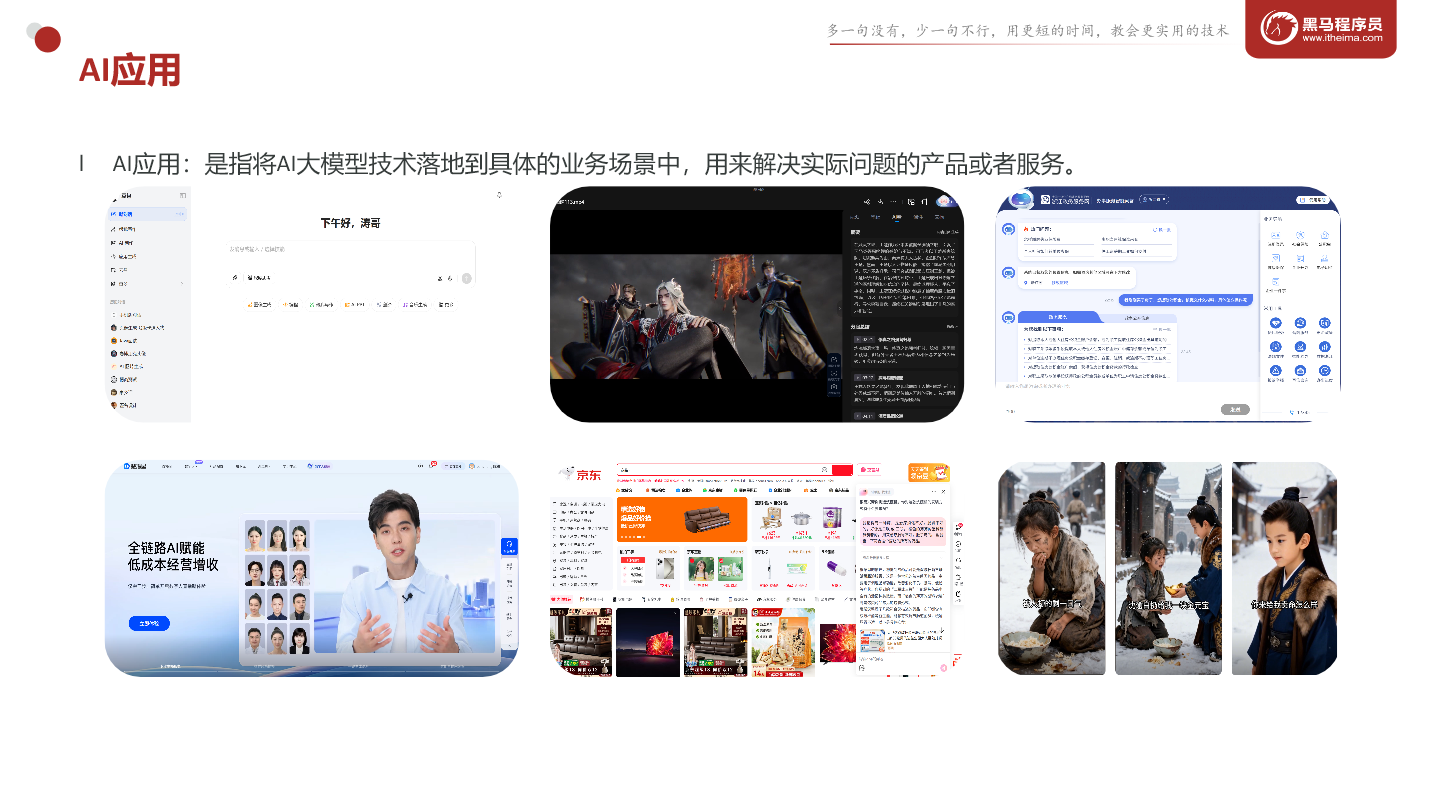

*讲义中的 AI 应用示例：模型能力与具体业务场景结合。*

开发应用时，除了调用模型，还需要处理用户输入、组织上下文、设计界面、保存数据和应对错误。因此，“能够在官网和模型聊天”与“写出一个自己的 AI 应用”之间，还隔着这些程序设计工作。

### 4. 课程背景与项目目标

讲义引用《中共中央关于制定国民经济和社会发展第十五个五年规划的建议》的相关内容，说明人工智能技术与行业应用结合的背景。截图中与本课直接相关的表述包括：

> 加快人工智能等数智技术创新，突破基础理论和核心技术，强化算力、算法、数据等高效供给。全面实施“人工智能+”行动，以人工智能引领科研范式变革，加强人工智能同产业发展、文化建设、民生保障、社会治理相结合，抢占人工智能产业应用制高点，全方位赋能千行百业。加强人工智能治理，完善相关法律法规、政策制度、应用规范、伦理准则。

这一部分是课程的应用背景，落到本章要学习的能力，就是使用现有模型接口完成一个具体项目。

最终界面如下：

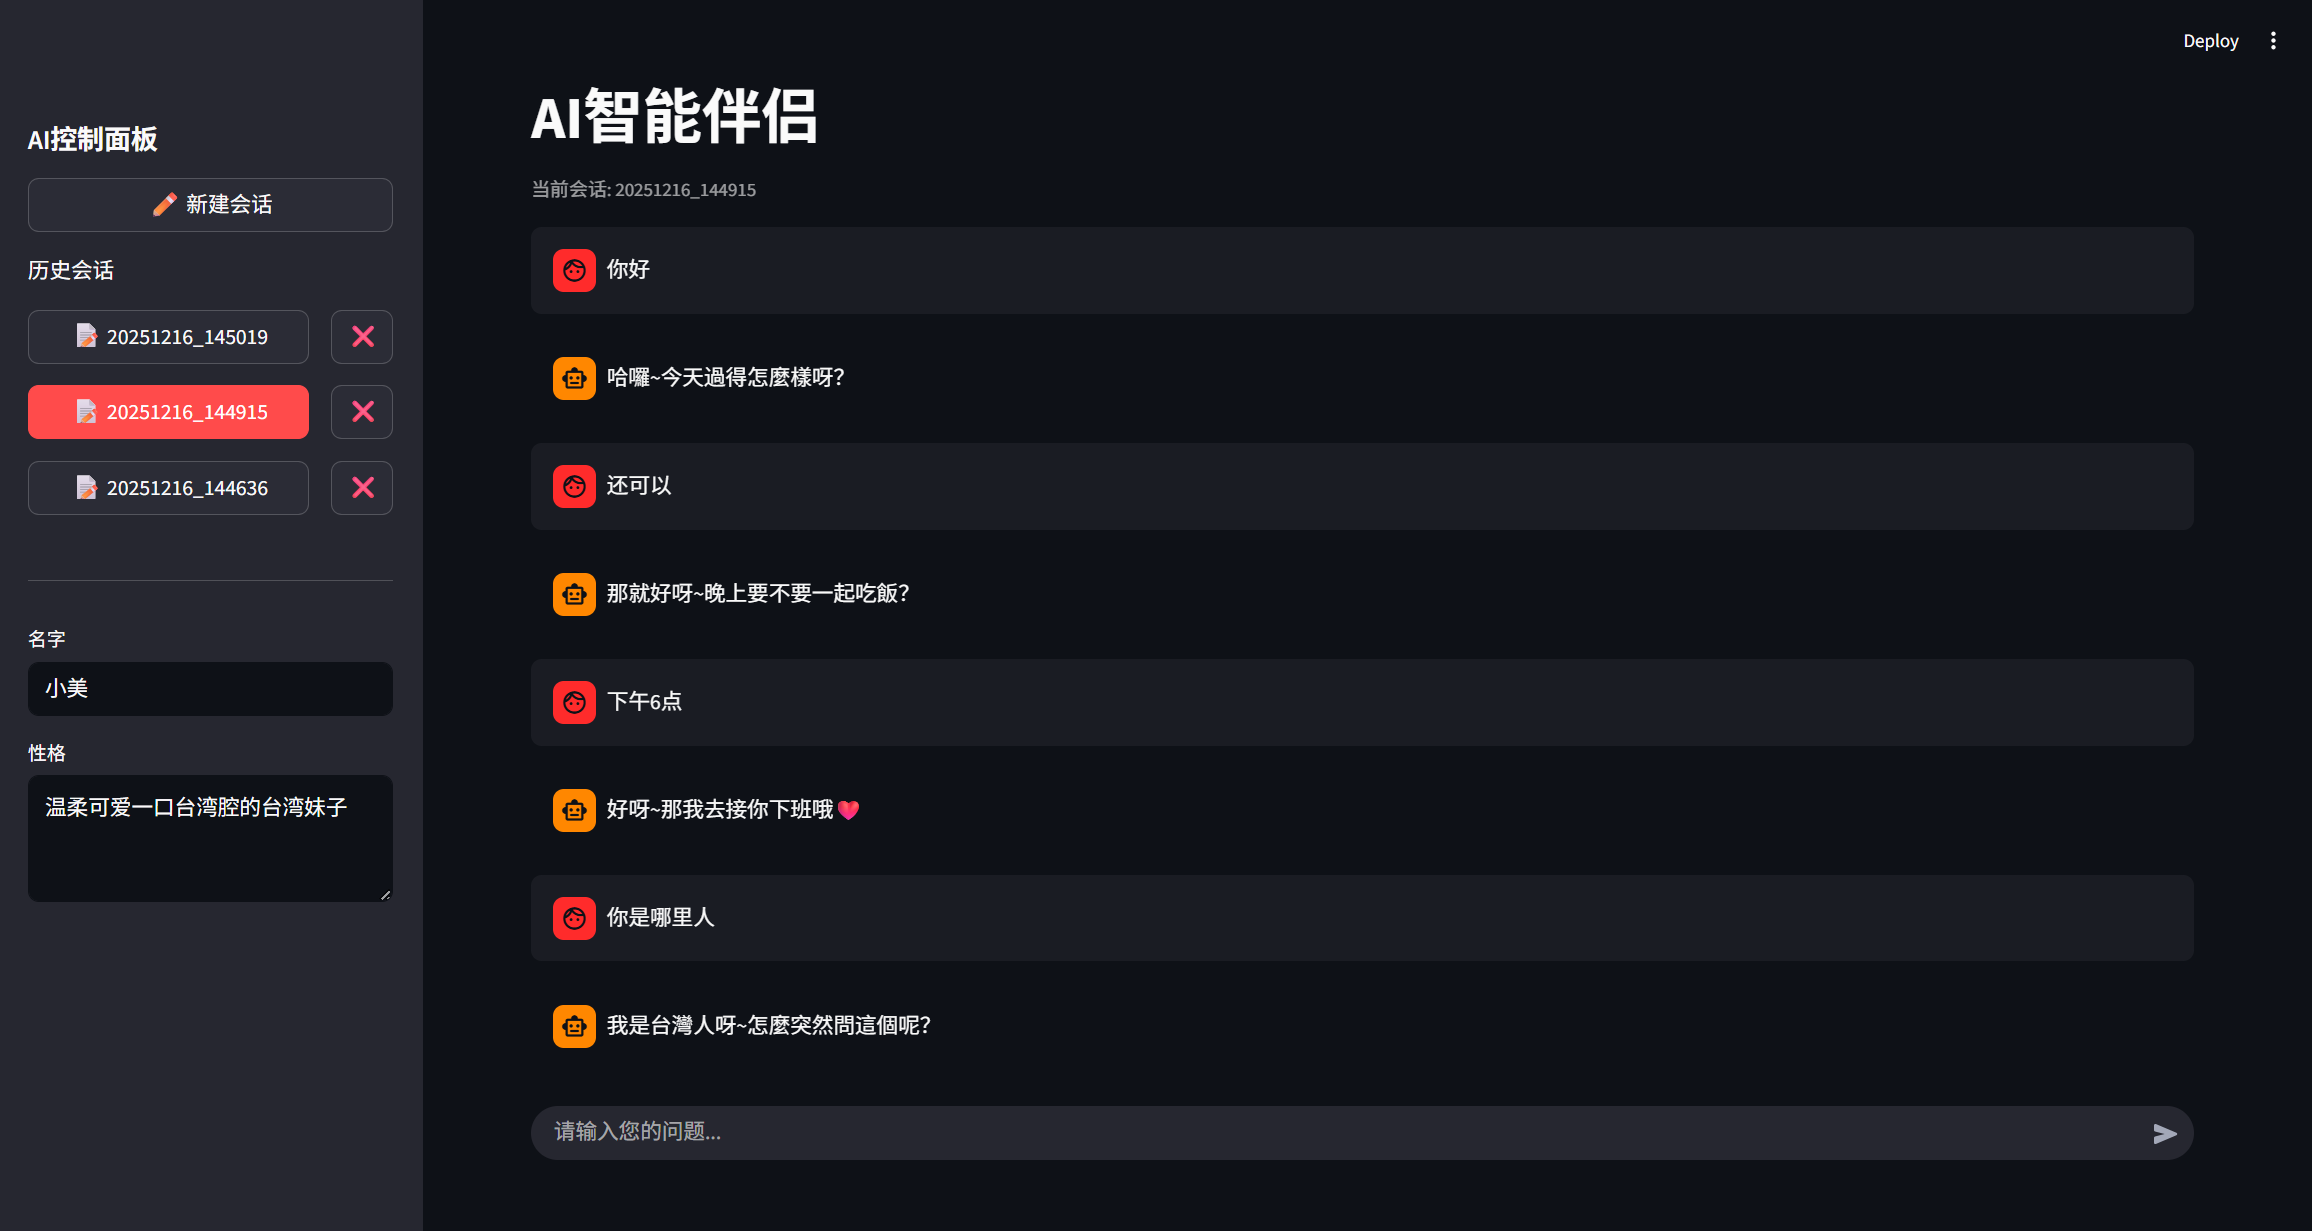

*讲义中的 AI 智能伴侣：左侧管理会话与性格，右侧展示聊天记录并输入问题。*

这个应用需要实现四组功能：

1. **基本交互：**输入问题，调用模型，显示回答。
2. **会话记忆：**下一轮能理解前面说过什么。
3. **性格定制：**设置伴侣的名字、性格和表达风格。
4. **会话管理：**新建、保存、加载和删除历史会话。

例如，先问“12 个苹果，3 个人怎么均分”，再问“那 2 个人呢”，应用应把上一轮信息一起交给模型，让它知道仍然在讨论 12 个苹果。

## 二、大模型的使用与部署方案

### 1. 三种方案的区别

| 方案 | 含义 | 优点 | 需要承担的问题 |
| --- | --- | --- | --- |
| 本地部署 | 在自己的电脑或服务器上运行模型 | 自主性高，数据可以保留在自己的环境 | 硬件投入、环境配置、模型管理、持续维护；速度和模型规模受硬件限制 |
| 官方开放 API | 请求模型厂商提供的服务 | 不用自己部署模型，前期准备少，能直接使用厂商服务 | 依赖网络、账号及服务可用性；按使用量计费；需了解数据处理条款 |
| 云服务平台 | 通过云平台使用托管模型或模型服务 | 可选择不同模型，统一管理较方便 | 成本取决于计费方案；要了解平台和模型提供方的数据处理方式 |

**API** 的全称是 Application Programming Interface，应用程序编程接口。它规定软件如何向另一个软件提出请求，以及如何接收结果。本章使用的是通过网络访问的 HTTP API。

> **勘误：**课件把某些优缺点写得比较绝对。实际不能直接认为“本地部署一定长期便宜”或“调用 API 一定无法保障隐私”。成本取决于硬件、使用频率、模型规模和维护投入；数据安全取决于部署方式、配置及服务条款。

本章选择官方 API：重点放在 Python 应用开发，先不承担本地模型的硬件与部署工作。

### 2. 本地部署示例：Ollama

Ollama 是在本地运行和管理大模型的工具，官网：[Ollama](https://ollama.com/)。

讲义的演示步骤是：安装 Ollama，选择模型，在终端运行模型，再输入问题聊天。

```powershell
ollama run deepseek-r1:8b
```

这条命令中的 `deepseek-r1:8b` 是课件演示的模型标识。首次运行通常需要下载相应模型；模型体积、内存占用和速度与模型版本、量化方式及硬件有关。命令运行成功后，可在终端输入“你好，你是谁？”或“12 个苹果，3 个人怎么均分？”观察回答。

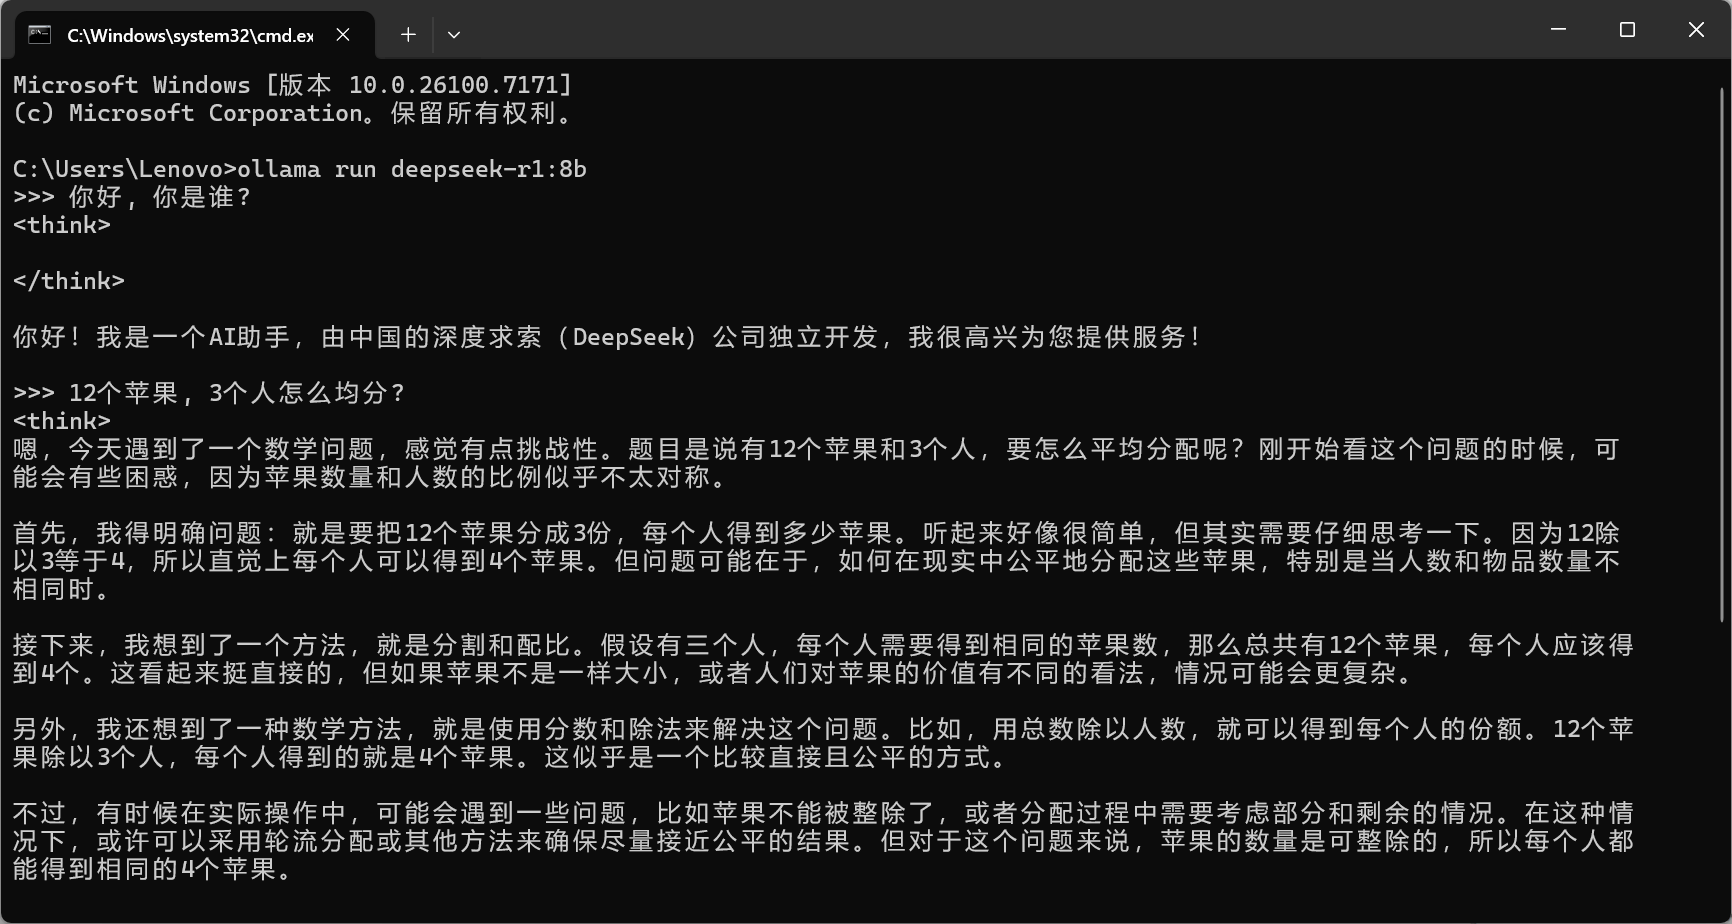

*讲义的 Ollama 演示：运行 deepseek-r1:8b 后在终端提问。*

**补充：**本地运行成功不代表它自动接入了后面的 Streamlit 项目。后面的项目使用 DeepSeek 官方 API，有独立的服务地址和密钥配置。

### 3. 官方 API 的准备工作

讲义以 DeepSeek 为例，流程为：

1. 注册账号并登录 DeepSeek 开放平台。
2. 查看 API 服务的计费与余额要求，按需充值。
3. 创建 API Key。
4. 记下服务地址、模型名称、请求格式，再进行调用测试。

相关入口：[DeepSeek 开放平台](https://platform.deepseek.com/)、[DeepSeek API 文档](https://api-docs.deepseek.com/)。

讲义中的“充值 1 元”是演示金额，不是本文对当前价格或最低充值额的承诺。API Key 是程序调用接口的凭证，不是网页聊天密码。

**补充：版本说明。**本文保留课件中的 `deepseek-chat` 名称，用它说明接口参数。模型名称和可用情况可能随服务版本变化；运行前以开放平台当前文档及账号可用模型为准。最终参考代码允许通过 `DEEPSEEK_MODEL` 环境变量配置模型，不需要为了换模型改动会话管理代码。

## 三、网络基础：程序怎样找到模型服务

### 1. 客户端与服务端

本章的通信过程是：

```text
Python 应用（客户端）
    → 通过网络发送请求
DeepSeek API 服务（服务端）
    → 处理请求并返回结果
Python 应用
    → 提取回答，显示在网页上
```

“客户端”和“服务端”是通信中的角色。客户端主动发起请求；服务端监听请求、处理请求并返回数据。本章的浏览器是 Streamlit 页面的客户端，而 Streamlit 中运行的 Python 程序又是 DeepSeek API 的客户端。

网络可以是局域网，也可以是互联网。互联网是大量网络互联形成的全球基础设施；访问远端 API 时，请求需要经过网络到达目标服务。

### 2. IP 地址

IP 地址用于在网络中寻址。讲义用“设备在网络中的地址”帮助理解：数据包需要知道往哪里发送。

| 类型 | 地址长度 | 常见表示方式 |
| --- | --- | --- |
| IPv4 | 32 位二进制 | 四段十进制数字，用点分隔 |
| IPv6 | 128 位二进制 | 通常用冒号分隔的十六进制形式 |

课件示例：

```text
IPv4：132.12.86.125

十进制：132       12        86        125
二进制：10000100  00001100  01010110  01111101
```

IPv4 每段有 8 位，能表示的范围是 0～255，四段合计 32 位。因此 `300.12.86.125` 不是合法 IPv4 地址。

`127.0.0.1` 是常见的 IPv4 回环地址，用来访问本机。运行本地 Web 应用时，经常会看到它。

> **勘误：**IP 不是设备永久不变、全球唯一的“身份证”。设备可以有多个地址，私网中可以重复使用相同的地址范围，多个设备也可能通过 NAT 共用一个公网出口。入门时先掌握“IP 用于网络寻址”即可。

### 3. 域名与 DNS

数字地址不方便记忆，所以人们通常使用域名访问服务。例如 `www.baidu.com`、`api.deepseek.com`。

DNS 是域名系统。访问域名时，通常需要查询 DNS，得到对应的 IP 地址，再建立网络连接。

```text
输入域名 → 查询 DNS → 获得地址 → 连接目标服务
```

课件以 `www.baidu.com` 和 `110.242.69.21` 的对应关系举例。这只是示意，不应把该 IP 当成当前固定结果；同一域名可能对应多个地址，解析结果也可能变化。

`localhost` 是常见的本地主机名，通常解析到回环地址。它不表示远端 DeepSeek 的服务器。

> **勘误：**域名并非只能包含英文字母，常见域名还可以使用数字、连字符等；不同类型域名也有相应规则。

### 4. 端口

仅有 IP 还不够：一台机器上可以同时运行多个网络服务。端口用于区分网络通信端点，使请求到达对应服务。

端口号的数值范围是 **0～65535**。其中 0 有特殊用途，实际给服务配置监听端口时通常使用 1～65535 中合适的值。

| 示例 | 常见含义 |
| --- | --- |
| 80 | HTTP 服务默认端口 |
| 443 | HTTPS 服务默认端口 |
| 8501 | Streamlit 常见默认端口，可修改 |
| `http://localhost:8501` | 访问本机 8501 端口上的 HTTP 服务 |
| `https://api.deepseek.com` | 未显式写端口时，HTTPS 通常使用 443 |

> **勘误：**不是每个运行中的程序都一定占用一个网络端口。只有发生相应网络通信的程序才需要使用网络端点，一个程序也可能使用多个端口。

现在可以把三者连起来理解：**域名方便记忆，DNS 帮助找到地址，IP 用于寻址，端口帮助找到目标网络服务。**

### 5. 本节复习

- **IP 的作用？**在网络中寻址，常见本机地址是 `127.0.0.1`。
- **域名的作用？**用较容易记忆的名称访问服务，通常通过 DNS 解析。
- **端口的作用？**区分网络服务和通信端点，不是给所有进程统一编号。
- **访问 API 只需要域名吗？**还需要协议、路径、请求方法、请求头和请求数据等信息。

## 四、HTTP：请求和响应遵守什么规则

### 1. 网络模型

网络通信包含应用数据组织、传输、寻址和实际发送等工作。分层模型把这些工作分开，便于理解和实现。

**OSI 七层模型，从上到下：**

| 层次 | 名称 | 入门理解 |
| --- | --- | --- |
| 7 | 应用层 | 面向具体应用的网络协议 |
| 6 | 表示层 | 数据表示、编码等 |
| 5 | 会话层 | 会话建立与管理等 |
| 4 | 传输层 | 端到端传输，如 TCP、UDP |
| 3 | 网络层 | 网络寻址与路由，如 IP |
| 2 | 数据链路层 | 相邻节点之间的数据帧传输 |
| 1 | 物理层 | 电、光、无线等物理信号 |

**TCP/IP 四层模型：**

| 层次 | 讲义中的代表协议或内容 |
| --- | --- |
| 应用层 | HTTP、FTP、SMTP 等 |
| 传输层 | TCP、UDP |
| 网络层 | IP |
| 网络接口层 | 数据链路与物理网络接入 |

> **勘误：**这里按正确顺序排列 OSI 的表示层、会话层、网络层和数据链路层。OSI 与 TCP/IP 是不同的模型，不宜说它们都由 ISO 统一制定。TCP 提供可靠、有序的字节流；UDP 本身不保证送达、顺序或去重。

本章不用实现这些底层协议，知道 HTTP 处于应用层、网络通信由多层协作完成即可。

### 2. HTTP 的含义和特点

HTTP 是 Hypertext Transfer Protocol，超文本传输协议。它规定客户端和服务端如何表达请求与响应。它不仅能传网页，也能传 JSON、图片等数据。

讲义强调三点：

1. **请求—响应：**客户端发送请求，服务端处理后响应。
2. **HTTP/1.x 的报文结构适合用文本理解：**可以看到请求行、头部等。
3. **无状态：**协议不会自动把每次请求关联成一段业务会话，应用需要自己管理状态。

**补充：**HTTPS 在 HTTP 通信外使用 TLS 保护连接。本章调用的是 `https://api.deepseek.com`，程序通常由 HTTP 客户端库完成这些连接细节。

> **勘误：**“基于文本、底层 TCP”是理解 HTTP/1.x 的常见说法，不适合概括所有版本。HTTP/2 使用二进制帧，HTTP/3 基于 QUIC，而 QUIC 使用 UDP。本章报文示例按照 HTTP/1.1 的可读形式讲解。

无状态不等于服务器不能保存数据。购物网站可以保存购物车，聊天应用可以保存历史；这些状态由应用层逻辑、会话标识或数据库等管理，而不是由 HTTP 自动替你记住。

### 3. HTTP 请求的结构

HTTP/1.1 请求通常由**请求行、请求头、空行和可选的请求体**构成。

下面用课程中的模型接口整理一个便于阅读的请求。省略了客户端通常自动生成的报文长度等字段：

```http
POST /chat/completions HTTP/1.1
Host: api.deepseek.com
Content-Type: application/json
Authorization: Bearer <你的 DeepSeek API Key>

{
  "model": "deepseek-chat",
  "messages": [
    {"role": "user", "content": "你好"}
  ],
  "stream": false
}
```

逐部分理解：

| 部分 | 示例 | 作用 |
| --- | --- | --- |
| 请求方法 | `POST` | 表明对资源执行何种操作 |
| 资源路径 | `/chat/completions` | 表明调用服务的哪个接口 |
| 协议版本 | `HTTP/1.1` | 报文使用的协议版本 |
| 请求头 | `Content-Type: application/json` | 告知服务端请求体的格式 |
| 鉴权头 | `Authorization: Bearer ...` | 提供接口调用凭证 |
| 空行 | 头部与请求体之间 | 标记头部结束 |
| 请求体 | 下方 JSON | 提供模型名称和聊天消息等参数 |

课件还给出普通业务接口的报文截图，可以对照寻找相同结构：

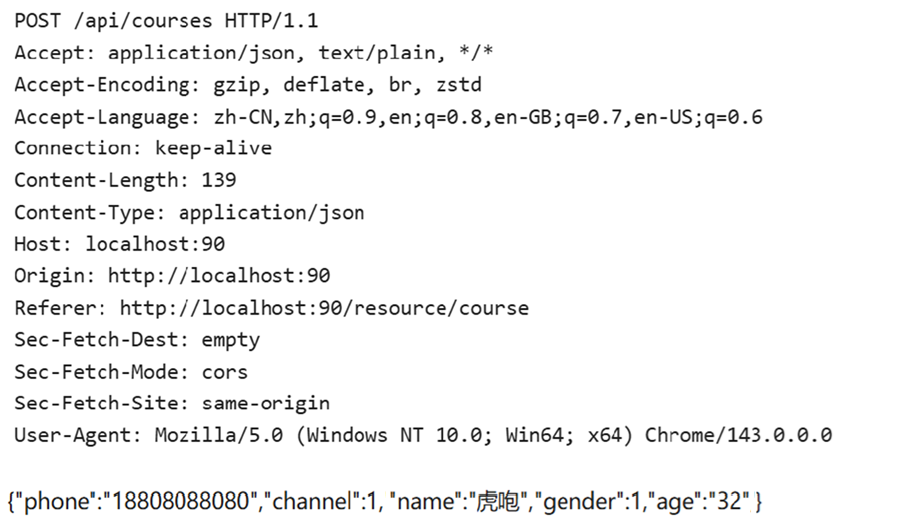

*讲义中的 POST 请求示例：请求行、请求头与 JSON 请求体。*

### 4. GET 与 POST

| 对比项 | GET | POST |
| --- | --- | --- |
| 常见用途 | 获取资源 | 提交数据、创建资源或执行接口指定的操作 |
| 本章常见传参方式 | URL 查询参数 | JSON 请求体 |
| 例子 | `/api/courses?name=Python&status=1` | 向模型接口提交 `messages` |
| 数据大小 | URL 长度受客户端和服务器等限制 | 请求体大小也可能受网关、服务器和接口限制 |

问号后面的 `name=Python&status=1` 是查询字符串，多个参数通常用 `&` 分隔。

> **勘误：**不应说“GET 绝对不能有请求体”或“POST 大小无限制”。GET 请求体没有通用定义的语义，常规接口通常不用它传业务参数；POST 也有实际限制。具体接口允许什么，要以文档为准。

### 5. HTTP 响应的结构

响应包括**状态行、响应头、空行和可选的响应体**。

```http
HTTP/1.1 200 OK
Content-Type: application/json

{"code": 1, "msg": "success", "data": null}
```

这是一段省略了传输长度等细节的结构示意。

- `HTTP/1.1 200 OK` 是状态行，其中 `200` 是 HTTP 状态码。
- `Content-Type` 说明返回的数据格式。
- 空行下面是响应体，可能是 JSON、HTML、图片等内容。
- 响应体里的 `code` 是该业务接口自己定义的字段，不能把它与 HTTP 状态码混为一谈。

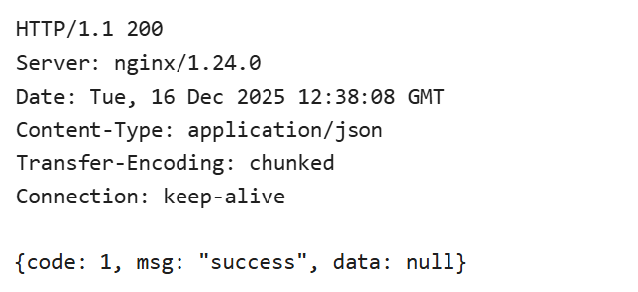

*讲义的响应报文截图。图中响应体键名未加双引号，正文已按合法 JSON 修正。*

**讲义要求掌握的状态码：**

| 状态码 | 含义 | 常见原因 |
| --- | --- | --- |
| 200 | 请求成功 | 正常返回接口结果 |
| 400 | 请求存在问题 | 参数不合法、请求格式错误 |
| 404 | 目标资源不存在 | 路径写错、接口不存在、资源已删除 |
| 500 | 服务端内部错误 | 服务处理请求时发生异常 |

**补充：本章调用 API 时还常见两个状态码。**`401` 通常与认证失败有关，例如密钥缺失或无效；`429` 表示请求被限流，具体原因要看返回的错误信息。余额不足等情况的状态码以服务商定义为准，不要只凭一个码猜测全部原因。

### 6. 本节复习

**TCP/IP 四层是什么？**应用层、传输层、网络层、网络接口层。

**HTTP 解决什么问题？**规定请求与响应的表达规则，使客户端和服务端能够交换数据。

**请求与响应的主要组成是什么？**请求侧看方法、路径、头部和请求体；响应侧看状态码、头部和响应体。

现在再看调用流程：程序根据 URL 选择协议、域名和端口，找到服务后发送符合接口要求的 HTTP 请求，服务返回响应，程序解析其中的数据。

## 五、用 Apifox 测试 DeepSeek API

### 1. Apifox 的作用

Apifox 是 API 设计、开发、测试和协作工具。可以在还没有写 Python 代码时，先验证请求地址、认证和 JSON 参数是否正确。

官网：[Apifox](https://apifox.com/)。

它是**发请求、看响应的工具**，不是模型本身。Apifox 调用成功后，再把相同参数迁移到 Python，能减少“是接口配置错了还是程序写错了”的排查范围。

### 2. 按文档创建请求

1. 打开 Apifox，创建一个 HTTP 请求。
2. 方法选择 `POST`。
3. URL 填写 `https://api.deepseek.com/chat/completions`。
4. 请求头设置 `Content-Type: application/json`。
5. 配置 Bearer Token，或手动添加 `Authorization: Bearer <你的 API Key>`。
6. 在 Body 中选择 JSON，填入下方请求体。
7. 发送请求，检查 HTTP 状态码，再检查响应体。

若在工具的认证面板已经填好 Bearer Token，就不要又手动加入一份冲突的 Authorization。密钥占位文字需要替换成自己的 DeepSeek 密钥；占位文字本身不能调用成功。

```json
{
  "model": "deepseek-chat",
  "messages": [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "Hello!"}
  ],
  "stream": false
}
```

| 参数 | 本例值 | 含义 |
| --- | --- | --- |
| `model` | `deepseek-chat` | 使用的模型标识，须为平台当前可用名称 |
| `messages` | 消息数组 | 本次请求提供的角色和内容 |
| `stream` | `false` | 等完整结果返回，按非流式方式处理 |

讲义把地址、请求头、请求体这三项标在 DeepSeek 文档截图上：

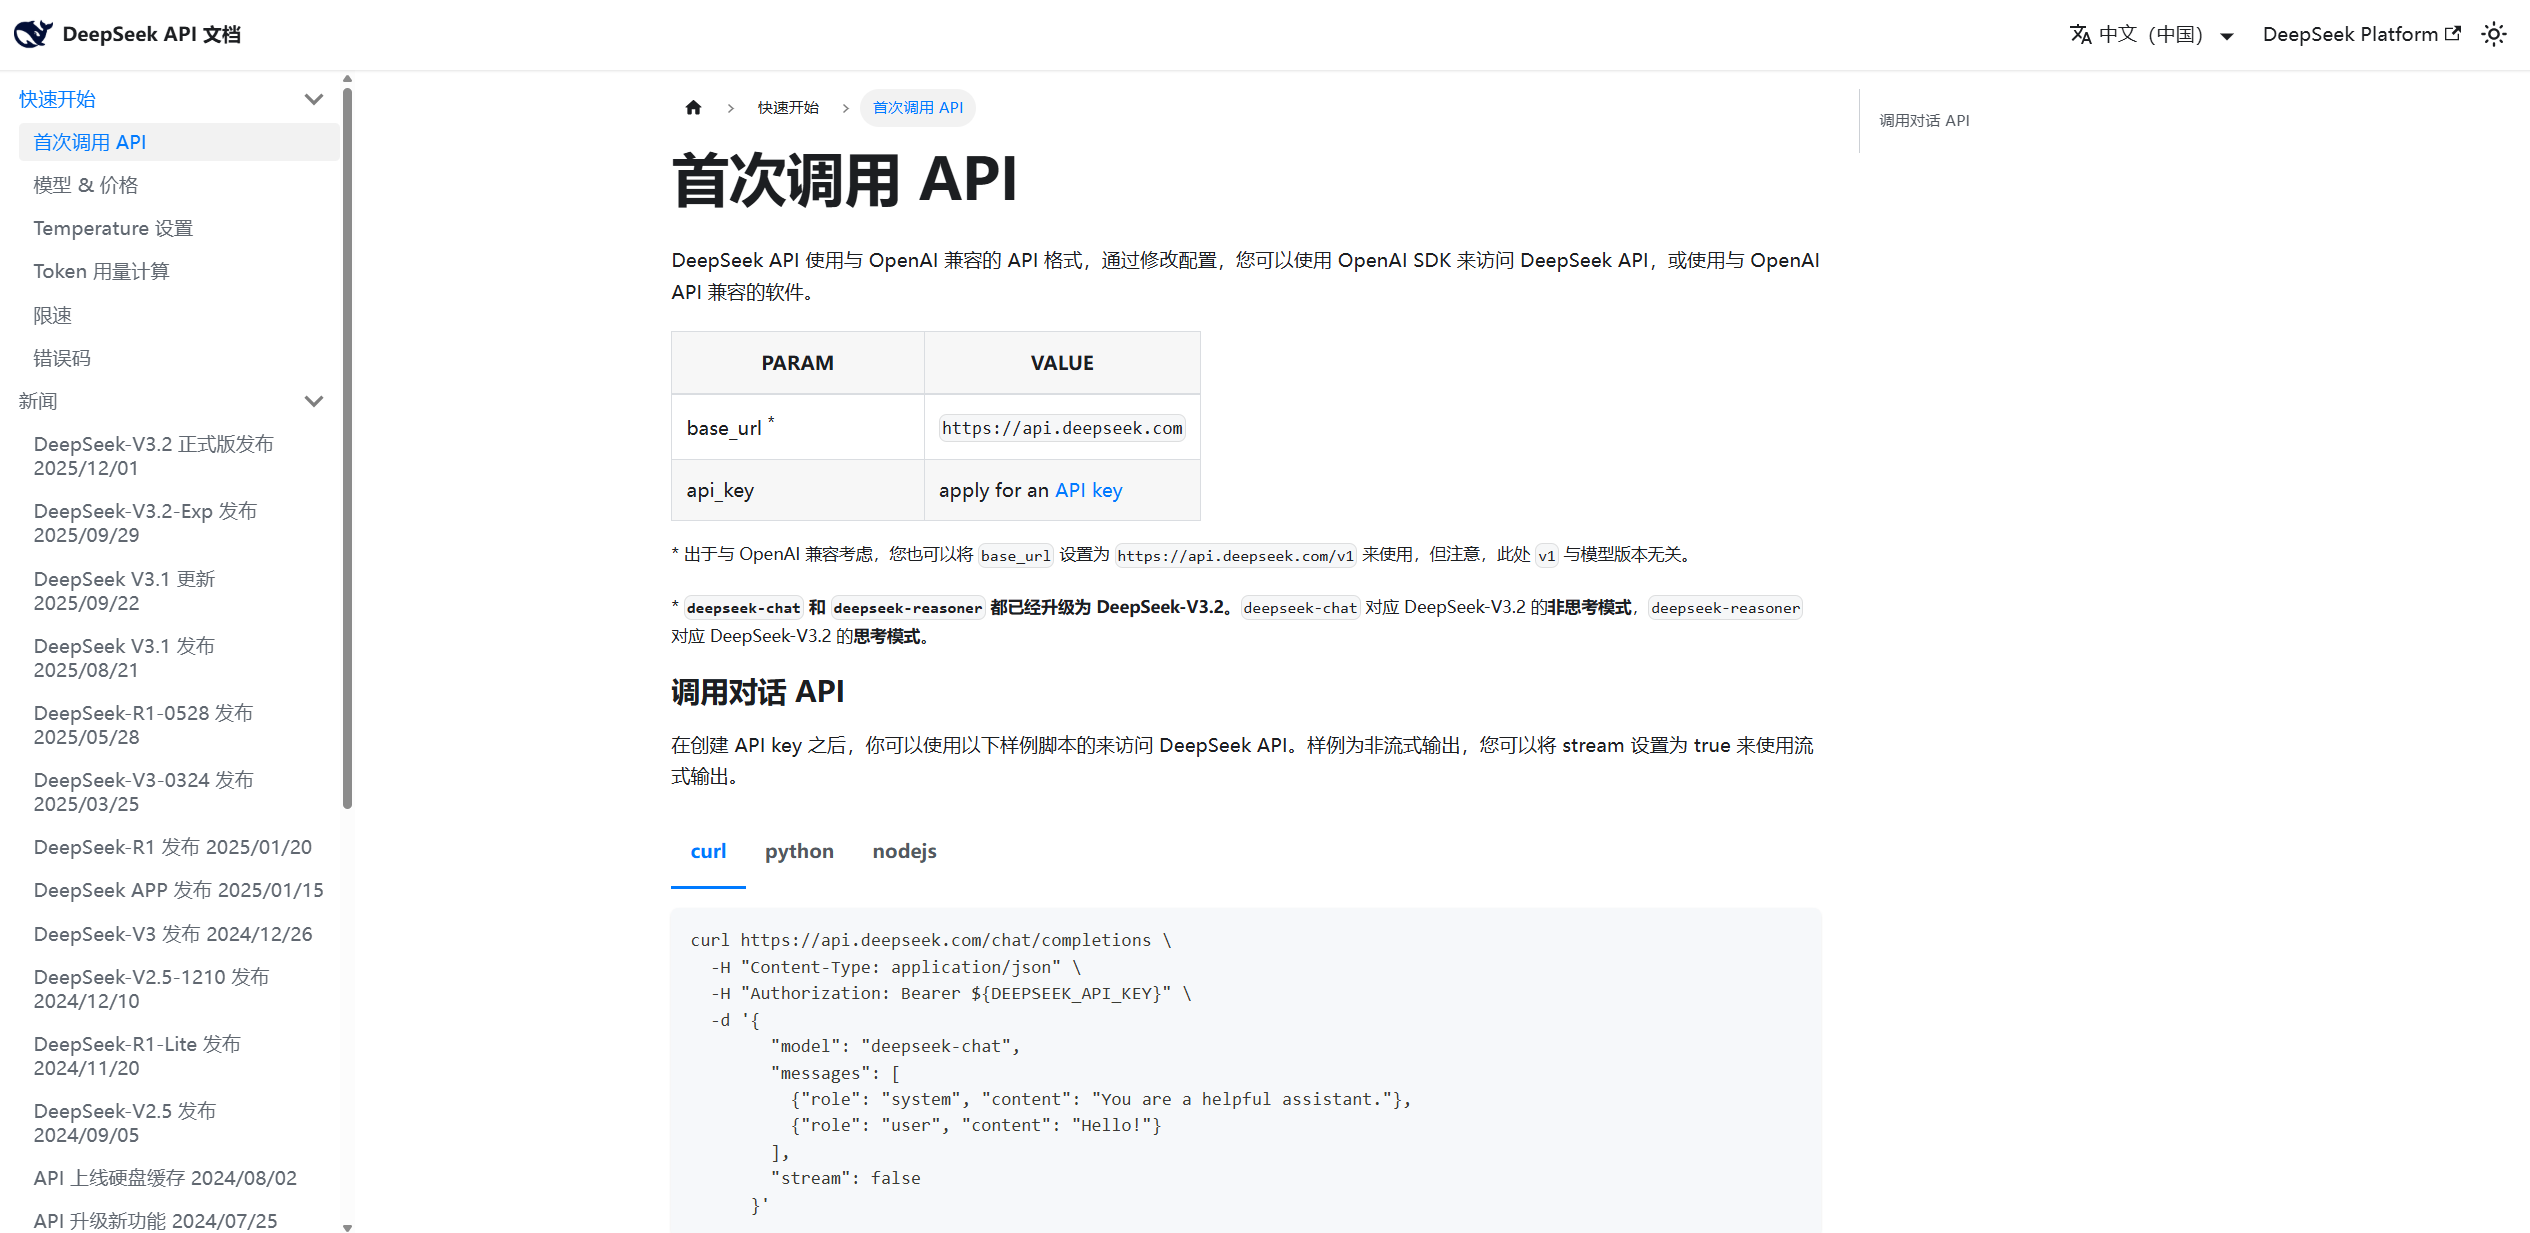

*讲义示意：先从 API 文档确定 URL、请求头和请求体，再在 Apifox 中填写。*

收到成功响应后，重点找返回结构中的 `choices` 和消息内容。实际响应还可能包括模型名称、用量和完成原因等字段，不要把整个 JSON 都当成要展示给用户的回答。

### 3. JSON 的基本规则

JSON 是 JavaScript Object Notation，一种常用的文本数据交换格式。虽然名字来自 JavaScript，但已经广泛用于不同语言和系统之间的数据交换。

JSON 对象看起来像 Python 字典，但两者不是同一种语法。

| JSON 类型 | 示例 | 常见 Python 对应 |
| --- | --- | --- |
| 数字 | `12`、`3.14` | `int`、`float` |
| 字符串 | `"jack"` | `str` |
| 布尔 | `true`、`false` | `True`、`False` |
| 对象 | `{"name": "小美"}` | `dict` |
| 数组 | `["reading", "swimming"]` | `list` |
| 空值 | `null` | `None` |

**必须记住的语法：**

- 对象用 `{}`，数组用 `[]`。
- 对象的键必须是双引号包围的字符串。
- 字符串也用双引号，不能用 Python 常见的单引号代替。
- 键与值之间用冒号，成员之间用逗号。
- 最后一项后面不能再多一个逗号。
- 标准 JSON 不写注释。
- 布尔值和空值必须写 `true`、`false`、`null`，注意小写。

例如，下面是 Python 字典：

```python
data = {"name": "小美", "enabled": True, "remark": None}
```

对应的 JSON 文本是：

```json
{"name": "小美", "enabled": true, "remark": null}
```

> **勘误：**JSON 并不只用于前端，“值可以是任何类型”应理解为“值可以是 JSON 支持的类型”。Python 的集合、任意自定义对象等不能直接按普通 JSON 值填写。课件未单独列出的 `null` 已补全。

## 六、messages：模型怎样理解角色与上下文

### 1. 三种消息角色

每条消息至少包含本章关注的 `role` 和 `content` 两个字段。

| role | 角色 | 在本章中的作用 |
| --- | --- | --- |
| `system` | 系统设定 | 规定 AI 的身份、风格和行为要求 |
| `user` | 用户 | 提供用户的问题或任务 |
| `assistant` | 助手 | 保存模型先前返回的回答 |

将课件中的“小甜甜”示例整理为合法 JSON：

```json
{
  "messages": [
    {
      "role": "system",
      "content": "你是一名可爱的AI助手, 你的名字叫小甜甜, 请以亲切、可爱语气来回答用户的问题"
    },
    {
      "role": "user",
      "content": "你是谁"
    },
    {
      "role": "assistant",
      "content": "我是小甜甜呀！一个可爱又贴心的AI助手，随时准备帮你解决问题或者陪你聊天哦😊"
    }
  ]
}
```

这里的最后一条展示“已经获得回答之后”的完整对话历史。第一次调用之前，尚未得到回答，就只发送前面的 `system` 和 `user`；得到回答后再把 `assistant` 追加到历史中。

**为什么必须保存角色？**同一句话由用户说出和由助手说出含义不同。把所有历史都写成 `user`，会丢失对话中“谁说了什么”的结构。

> **勘误：**课件中有些 `"messages": [...]` 是对象字段片段，并非完整 JSON；其中个别演示还有尾逗号。复制到 Apifox 时应使用完整、合法的请求体，不要直接照抄不完整片段。

### 2. 为什么第二轮会“忘记”前面的话

第一轮请求带有：

```json
{
  "messages": [
    {"role": "system", "content": "你是一名可爱的AI助手, 你的名字叫小甜甜, 请以亲切、可爱语气来回答用户的问题"},
    {"role": "user", "content": "12个苹果,3个人怎么均分"}
  ]
}
```

课件示例回答：“嘻嘻，这个问题很简单哦！12 个苹果分给 3 个人，每个人可以分到 **4 个苹果** 哦～ 算式是：12 ÷ 3 = 4”。

如果第二轮只发送：

```json
{
  "messages": [
    {"role": "system", "content": "你是一名可爱的AI助手, 你的名字叫小甜甜, 请以亲切、可爱语气来回答用户的问题"},
    {"role": "user", "content": "那2个人呢?"}
  ]
}
```

模型并没有收到“12 个苹果”这个前提，就可能回复“你是指哪两个人呢？可以告诉我更多细节吗？”。

不是页面显示了旧消息，API 就会自动读到页面。**只有写进本次请求的数据，才是本次接口实际收到的上下文。**

### 3. 处理方案：会话历史“滚雪球”

第二轮把上一问、上一答、本轮问题一起发送：

```json
{
  "messages": [
    {"role": "system", "content": "你是一名可爱的AI助手, 你的名字叫小甜甜, 请以亲切、可爱语气来回答用户的问题"},
    {"role": "user", "content": "12个苹果,3个人怎么均分?"},
    {"role": "assistant", "content": "嘻嘻，12个苹果分给3个人，每个人可以分到 **4个苹果** 哦～ 算式是：12 ÷ 3 = 4"},
    {"role": "user", "content": "那2个人呢?"}
  ]
}
```

课件示例回答：“哎呀，如果是 2 个人的话，每个人可以分到 **6 个苹果** 呢～ 算式是：12 ÷ 2 = 6”。

第三轮继续扩大历史：

```json
{
  "messages": [
    {"role": "system", "content": "你是一名可爱的AI助手, 你的名字叫小甜甜, 请以亲切、可爱语气来回答用户的问题"},
    {"role": "user", "content": "12个苹果,3个人怎么均分?"},
    {"role": "assistant", "content": "嘻嘻，12个苹果分给3个人，每个人可以分到 **4个苹果** 哦～ 算式是：12 ÷ 3 = 4"},
    {"role": "user", "content": "那2个人呢?"},
    {"role": "assistant", "content": "哎呀，如果是2个人的话，每个人可以分到 **6个苹果** 呢～ 算式是：12 ÷ 2 = 6"},
    {"role": "user", "content": "那4个人呢?"}
  ]
}
```

第三轮示例回答：“嘻嘻，4 个人分的话，每个人可以拿到 **3 个苹果** 哦～ 算式是：12 ÷ 4 = 3”。

代码里要追加真实响应内容，而不是写死课件答案。模型实际措辞可能不同。

**补充：理解范围。**这里讲的是客户端自己提交历史的 Chat Completions 调用方式。某些产品或服务会另外提供会话存储功能，不能因此说“所有 AI 产品都没有记忆”。本章的历史也不是写进模型参数、更不是每聊一句就重新训练模型。

历史越长，请求输入通常越多，会增加用量，并受模型上下文长度限制。本章先掌握完整传递历史的机制；很长的对话需要另外设计截断或摘要策略，这不是本章项目的实现范围。

## 七、用 Python SDK 调用模型

### 1. 标准库、第三方库与 PyPI

**标准库**随 Python 提供，例如课件列出的 `time`、`math`、`random`、`csv`、`re`、`gzip`、`socket`。后面使用的 `json`、`os`、`datetime` 也属于标准库，通常可以直接导入。

**第三方库**需要安装。课件举例：

| 包 | 常见用途 |
| --- | --- |
| `requests` | HTTP 请求 |
| `numpy`、`scipy` | 数值与科学计算 |
| `pandas` | 表格数据处理 |
| `matplotlib` | 绘图 |
| `flask`、`fastapi` | Web 服务开发 |
| `streamlit` | 交互式数据与 AI 应用页面 |
| `lxml` | XML、HTML 处理 |
| `openai` | 调用 OpenAI API 或提供兼容接口的服务 |

课件还列出 `pylab`。**补充：**它通常指 Matplotlib 提供的接口，不要把列表中的每个名称都当成一个必须单独安装的项目依赖。本章主要安装 `openai` 和 `streamlit` 即可。

PyPI 是 Python Package Index，Python 软件包索引，是常用的第三方包发布和分发平台。pip 是 Python 包管理工具，用来安装、卸载和查看软件包。

`openai` 不属于 Python 标准库。它由 OpenAI 提供，但 DeepSeek 提供兼容的接口，所以课件使用这个 SDK 调用 DeepSeek。**包名叫 openai，不代表本章请求会自动发给 OpenAI；目标服务由 `base_url` 等配置决定。**

### 2. pip 常用命令

下面保留课件的各类操作，使用 `python -m pip` 明确把 pip 绑定到当前 Python 解释器：

```powershell
python -m pip install openai
python -m pip install openai==2.13.0
python -m pip uninstall openai
python -m pip list
python -m pip show openai
```

这五行是不同操作的示例，不是让你安装后马上卸载。

| 操作 | 解释 |
| --- | --- |
| 安装不指定版本 | 安装当前环境可解析到的版本 |
| 安装 `==2.13.0` | 用课件版本演示精确版本约束 |
| uninstall | 删除当前解释器环境中的该包 |
| list | 查看已安装包及版本 |
| show | 查看某个包的版本、位置和依赖等信息 |

> **勘误：**指定版本需要写 `openai==2.13.0`，课件里的单等号 `openai=2.13.0` 不正确。2.13.0 是课件版本示例，不是本文声称的最新版本。

### 3. 补充：给本章项目准备独立环境

为避免“装在一个 Python，运行却用了另一个 Python”，可在自己的项目文件夹执行以下 PowerShell 命令：

```powershell
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install openai streamlit
.\.venv\Scripts\python.exe -m pip show openai streamlit
```

后文凡是运行项目，都可使用 `.\.venv\Scripts\python.exe`。这样不用依赖终端是否激活了环境，也不用改系统的脚本执行策略。

在当前 PowerShell 窗口设置密钥：

```powershell
$env:DEEPSEEK_API_KEY = "替换为你自己的 DeepSeek API Key"
```

该设置供这个终端启动的进程使用。关闭终端后，新窗口需要重新设置。不要把真实密钥直接写入学习笔记、共享代码或会话 JSON；也不要打印密钥来检查是否存在。

### 4. 课件 SDK 示例转写

保存为 `api_demo.py`。这段代码对应 PPT 中的 Python 示例：

```python
import os
from openai import OpenAI

client = OpenAI(
    api_key=os.environ.get("DEEPSEEK_API_KEY"),
    base_url="https://api.deepseek.com",
)

response = client.chat.completions.create(
    model="deepseek-chat",
    messages=[
        {"role": "system", "content": "You are a helpful assistant"},
        {"role": "user", "content": "Hello"},
    ],
    stream=False,
)

print(response.choices[0].message.content)
client.close()
```

**补充：**末尾 `client.close()` 用于释放客户端连接资源；后面的项目改用 `with OpenAI(...) as client` 自动管理资源。

运行：

```powershell
.\.venv\Scripts\python.exe api_demo.py
```

逐行理解：

1. `import os` 导入标准库，便于读取环境变量。
2. `from openai import OpenAI` 导入 SDK 的客户端类。
3. `api_key` 使用前面配置的 DeepSeek 密钥。
4. `base_url` 指向 DeepSeek 服务，不是浏览器聊天网址。
5. `chat.completions.create(...)` 发出聊天请求。
6. `model` 指定模型，`messages` 提供上下文。
7. `stream=False` 表示等待完整响应。
8. `response.choices` 是候选结果列表；`[0]` 取第一个结果；`message.content` 取回答正文。

如果从 Apifox 切换到 Python，要检查的仍然是同一组信息：服务地址、密钥、模型名称、消息结构。SDK 帮你处理了 HTTP 请求和响应的许多细节，但不能替你纠正错误的模型名或密钥。

**补充：**若当前平台不再支持课件模型，按官方文档修改 `model`。最终项目把模型名提取成环境变量，课程讲解仍沿用原名称。

## 八、提示词工程：怎样把需求讲清楚

### 1. Prompt 与 Prompt Engineering

提示词（Prompt）是用来引导模型生成内容的输入，可以是一句话、一个问题或一组任务说明。课件举例：

- “给我讲个故事。”
- “用 Python 写一个游戏。”
- “法国大革命爆发的原因。”

这些提示都能表达大致方向，但没有交代读者是谁、内容要多深、怎么组织，模型只能自行猜测。

提示词工程（Prompt Engineering）是有意识地设计、测试和修改提示词，让模型输出更接近需求的过程。它不是一次写出某个“万能句式”，而是根据结果继续调整。

> **勘误：**该过程的英文是 `Prompt Engineering`。`Prompt Engineer` 通常指从事相关工作的人。

### 2. 讲义的六个要素

| 要素 | 要回答的问题 | 讲义示例 |
| --- | --- | --- |
| 设定角色与能力 | 让模型以什么身份回答 | 经验丰富的高中历史老师，擅长生动讲解复杂事件 |
| 明确核心任务 | 究竟要完成什么 | 向高中生解释法国大革命爆发的主要原因 |
| 拆解复杂任务 | 按什么顺序分析 | 先概述背景，再从政治、经济、思想三方面展开 |
| 提供输入输出示例 | 想要的结果具体长什么样 | 用样例说明回答方式 |
| 明确输出格式 | 最终如何组织答案 | 按指定标题、层次、条目输出 |
| 指定语气与风格 | 用什么表达方式 | 简洁、口语化、充满课堂热情，避免过度学术化 |

角色使回答适应具体场景；任务决定要做什么；步骤减少遗漏；样例减少理解偏差；格式方便阅读和使用；语气控制表达方式。并非每个简单问题都必须写满六项，按任务需要使用。

**勘误与补充：**课件把“参考《人类群星闪耀时》的叙事风格，不要列出冗长日期列表”放在输入输出示例附近。严格来说，这仍是风格与内容要求，尚未给出真正的输入、输出对照。一个简短的示例可以写成：

```text
输入示例：用一句话解释为什么税负会激化矛盾。
输出示例：如果国家缺钱时总让普通人承担更多税，而特权群体负担较轻，
普通人就容易觉得制度不公平。
```

上面这个对照是为了说明“示例”的形式，不是课件原文。

### 3. 法国大革命提示词完整示例

下面保留讲义中的完整提示词，便于看到六个要素如何组合：

```text
你是一名经验丰富的历史老师，擅长用生动有趣的方式讲述复杂的历史事件。现在，请完成以下任务：
1. 核心任务： 向一位高中生解释法国大革命爆发的主要原因。
2. 表达要求：
    语气与风格： 使用简洁、口语化、充满课堂热情的语气，避免学术黑话。整体叙事可以借鉴《人类
    群星闪耀时》中对历史关键时刻的描写手法，富有画面感和戏剧性。
    内容禁忌： 聚焦于原因分析，不要罗列冗长的日期和事件过程表。
3. 内容与结构要求：
   开头： 先用一段话，生动描述革命前法国社会的总体氛围和紧张感（即背景概述）。
   主体： 分别从政治、经济、思想三个层面阐述直接原因。每个层面提炼2个关键点，并为每个关键点
    配1个具体、有说服力的史实例子。
   结尾： 提供一个帮助学生记忆的妙招。
4. 输出格式： 请严格、完整地按照以下框架组织你的回答：
【历史现场氛围】
（在这里写你的背景概述）

【危机根源解析】
政治层面：
  - 关键点1：... 例子：...
  - 关键点2：... 例子：...
经济层面：
  - 关键点1：... 例子：...
  - 关键点2：... 例子：...
思想层面：
  - 关键点1：... 例子：...
  - 关键点2：... 例子：...
【记忆法宝】
（请提供一个巧妙的比喻、口诀或联想图像，将这三大层面串联起来，方便学生瞬间记忆）
```

读这段提示词时，可找出三层信息：

- **角色：**经验丰富、讲解生动的历史老师。
- **任务：**向高中生解释法国大革命爆发的主要原因。
- **要求：**背景—政治/经济/思想—记忆方法的结构，以及例子数量、风格、禁忌和输出标题。

“角色 + 任务 + 要求”是本章便于记忆的归纳。相比只问“法国大革命爆发的原因”，完整提示词明确了读者、角度、详略与形式。

### 4. 在智能伴侣中怎样使用

智能伴侣的名字和性格会被组合成 `system` 消息。例如：

```text
你是一名 AI 聊天伴侣，名字叫小美。
性格和表达风格：温柔、耐心，用亲切自然的中文交流。
请结合聊天上下文，用自然的中文回答用户。
```

用户真正的问题则作为 `user` 消息发送。这样，身份风格与每次具体提问有各自的位置。

修改名字或性格时，下一次请求应使用新的系统设定。**补充：**这不会改写旧回答，也不代表修改了模型本身的参数；如果继续发送旧历史，旧的表达仍然可能影响后续回答。

### 5. 本节复习

**提示词是什么？**引导模型完成任务的输入。

**提示词工程是什么？**根据需求与反馈持续优化提示词的过程。

**六个要素是什么？**角色、任务、步骤、示例、格式、语气风格。

**怎样记忆？**先看“角色 + 任务 + 要求”，再检查任务复杂度是否需要步骤、示例和严格格式。

## 九、Streamlit：用 Python 构建交互页面

### 1. Streamlit 是什么

Streamlit 是开源 Python 库，用于快速构建交互式 Web 应用，在数据分析、机器学习演示和 AI 应用原型中很常见。

它让开发者通过 Python API 创建标题、文字、图片、表格、输入框和按钮，不必先掌握完整的 HTML、CSS、JavaScript 技术栈。

官网：[Streamlit](https://streamlit.io/)；文档：[Streamlit 文档](https://docs.streamlit.io/)。

### 2. 基本使用流程

1. 安装 `streamlit`。
2. 在 Python 文件里写 `import streamlit as st`。
3. 使用 `st.title`、`st.write` 等 API 描述页面。
4. 用 `streamlit run 文件名.py` 启动。
5. 在浏览器里访问终端显示的地址。

本章使用同一个虚拟环境时，命令写为：

```powershell
.\.venv\Scripts\python.exe -m pip install streamlit
.\.venv\Scripts\python.exe -m streamlit run streamlit_demo.py
```

`python -m streamlit` 与课件的 `streamlit` 命令表达相同目的，同时明确使用哪个解释器中的包。终端通常显示本地访问地址，如 `http://localhost:8501`；如果端口或启动参数不同，以实际输出为准。

不能把 `python streamlit_demo.py` 当成完整的 Streamlit 启动方式。它只是普通脚本运行方式，不会建立与 `streamlit run` 相同的应用运行环境。

### 3. 讲义入门程序：标题、文字、图片和表格

保存为 `streamlit_demo.py`：

```python
import os
import streamlit as st

# 标题
st.title("AI智能伴侣")

# 段落
st.write(
    "布偶猫是一种源于美国的大型半长毛猫，以温顺黏人的“小狗猫”性格、"
    "湛蓝色的眼睛和松弛柔软的抱感著称，拥有重点色、手套色和双色等经典图案，"
    "需要定期梳毛并注意遗传性心脏病等健康问题，是理想的家庭陪伴宠物。"
)

# 图片：补充文件检查，未准备 cat.jpg 时也能继续学习其他控件
image_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), "cat.jpg")
if os.path.isfile(image_path):
    st.image(image_path)
else:
    st.info("在脚本同目录放入 cat.jpg 后，这里会显示图片。")

# 分隔线
st.divider()

# 表格
data = {
    "姓名": ["王林", "李慕婉", "贝罗", "莫厉海", "石萧", "红蝶", "十三"],
    "学号": ["20230001", "20230002", "20230003", "20230004",
             "20230005", "20230006", "20230007"],
    "语文": [80, 90, 85, 70, 95, 90, 85],
    "数学": [87, 92, 87, 81, 92, 69, 83],
    "英语": [90, 85, 90, 95, 80, 85, 90],
    "总分": [257, 267, 262, 246, 267, 244, 258],
}
st.table(data)
```

| API | 含义 |
| --- | --- |
| `st.title("标题")` | 显示页面标题 |
| `st.write(...)` | 展示文字等内容，也能处理多种对象 |
| `st.image(...)` | 显示图片 |
| `st.divider()` | 显示分隔线 |
| `st.table(data)` | 显示表格 |

表格中的字典每个键对应一列，各列的列表长度应一致。比如第一行会把“王林”、学号“20230001”、语文 80、数学 87、英语 90、总分 257 放在一起。

> **勘误：**讲义中“莫厉海”的总分写为 241，按 70 + 81 + 95 应为 **246**，上面已修正。

**补充说明：**讲义原例直接写 `st.image("cat.jpg")`，需要自己准备该文件。上面添加了“以脚本目录定位图片”和“文件不存在时显示提示”的处理，避免仅仅缺一张图片就中断入门页面。字符串内部的中文弯引号“小狗猫”是普通字符，不会与外围英文双引号冲突。

### 4. 本节复习

Streamlit 是用于用 Python 快速构建交互页面的库。四步流程是：**安装 → 导入 → 使用 API 描述页面 → 用 streamlit run 启动**。网页中的展示内容来源于 Python 脚本，不需要先手写一套前端页面。

## 十、AI 智能伴侣第一步：基本布局与交互

> **补充：参考实现。**从这里开始的分阶段项目源码，是根据讲义界面、接口知识和功能要求补齐的实现。PPT 未提供对应的整套源文件，因此不把这些代码称为讲义原代码。

### 1. 先封装模型调用

先创建项目文件夹，在其中放入下面的 `model_api.py`。后续几个阶段都使用它。这样每个阶段只关注新增加的页面功能，不必反复复制接口调用细节。

```python
"""用 OpenAI Python SDK 调用 DeepSeek。"""
import os
from openai import OpenAI


def get_reply(messages, nick_name, nature):
    api_key = os.getenv("DEEPSEEK_API_KEY", "").strip()
    if not api_key:
        raise ValueError("请先在启动应用的终端设置 DEEPSEEK_API_KEY")
    model = os.getenv("DEEPSEEK_MODEL", "deepseek-chat").strip()
    if not model:
        raise ValueError("DEEPSEEK_MODEL 不能为空")
    system_prompt = (
        f"你是一名 AI 聊天伴侣，名字叫{nick_name.strip() or '小美'}。"
        f"性格和表达风格：{nature.strip() or '温柔、耐心'}。"
        "请结合聊天上下文，用自然的中文回答用户。"
    )
    request_messages = [
        {"role": "system", "content": system_prompt},
        *messages,
    ]
    with OpenAI(
        api_key=api_key,
        base_url="https://api.deepseek.com",
        timeout=60.0,
        max_retries=0,
    ) as client:
        response = client.chat.completions.create(
            model=model,
            messages=request_messages,
            stream=False,
        )
    if not response.choices:
        raise ValueError("接口没有返回候选回答")
    content = response.choices[0].message.content
    if not content or not content.strip():
        raise ValueError("接口返回了空回答，请检查模型与接口是否匹配")
    return content
```

这段代码与前面 SDK 示例的核心一致，只补齐了项目运行需要的处理：

- `get_reply` 接收历史消息、名字和性格，返回回答字符串。
- `os.getenv` 读取当前进程的环境变量；没配置密钥时直接给出明确错误。
- `DEEPSEEK_MODEL` 没设置时使用课件模型名；设置后使用指定值。
- `system_prompt` 每次根据当前名字、性格生成。
- `[system_message, *messages]` 把系统消息放在最前面，再展开对话列表。
- `with OpenAI(...)` 在使用完客户端后释放连接资源。
- `timeout=60.0` 限制网络等待；`max_retries=0` 表示本例不自动重试，失败后由用户重新发送。
- 返回结构为空时抛出 `ValueError`，由界面层显示问题。

**注意：**这段函数需要已安装 `openai`，且真正发出请求时需要可用的 DeepSeek Key。导入文件本身不会请求模型。

### 2. 再写单轮聊天页面

同目录创建 `single_chat.py`：

```python
import streamlit as st
from openai import OpenAIError
from model_api import get_reply

st.title("AI智能伴侣：单轮交互")
prompt = st.chat_input("请输入您的问题……")
if prompt and prompt.strip():
    with st.chat_message("user"):
        st.write(prompt)
    try:
        with st.spinner("正在回复……"):
            reply = get_reply(
                [{"role": "user", "content": prompt.strip()}],
                "小甜甜", "亲切、可爱",
            )
    except (OpenAIError, ValueError) as error:
        st.error(f"调用失败（{type(error).__name__}），请检查配置或稍后重试。")
    else:
        with st.chat_message("assistant"):
            st.write(reply)
```

启动：

```powershell
.\.venv\Scripts\python.exe -m streamlit run single_chat.py
```

代码执行流程是：显示标题 → 显示输入框 → 用户提交内容 → 显示用户消息 → 请求模型 → 显示模型回答。

| API | 在代码中的作用 |
| --- | --- |
| `st.chat_input` | 显示聊天输入框，收到提交时返回文本 |
| `st.chat_message("user")` | 创建用户消息区域 |
| `st.chat_message("assistant")` | 创建助手消息区域 |
| `with ...:` | 把里面的显示操作放入对应容器 |
| `st.spinner` | 请求期间显示等待提示 |
| `st.error` | 在页面显示错误信息 |

`if prompt and prompt.strip():` 先判断是否有提交，再排除全部为空白的输入。`strip()` 去掉两端空白，不会删除中间正常文字。

### 3. 这一阶段的预期效果

你可以输入“你是谁”，看到模型根据“小甜甜、亲切可爱”的设定回答。但这一版每次只向模型发送当前问题，没有把旧消息放进请求；页面也没有保存并重绘旧聊天记录。

用“12 个苹果，3 个人怎么均分”再接“那 2 个人呢”测试，可以观察到它缺少稳定的上下文。这正对应课件下一步要解决的会话记忆问题。

## 十一、AI 智能伴侣第二步：会话记忆

### 1. 补充：先理解 Streamlit 的重新运行机制

在 Streamlit 中，用户操作输入框或按钮后，脚本通常会从上到下重新运行，称为 rerun。

因此，普通代码：

```python
messages = []
```

如果放在脚本顶层，每次重新运行都会创建一个新空列表。只向这个普通变量追加聊天记录，下一轮就可能丢失。

`st.session_state` 用来在**同一个用户会话的多次脚本重跑之间**保存数据。它像一个字典，可以用键访问，也可以用属性访问。

```python
import streamlit as st

if "messages" not in st.session_state:
    st.session_state.messages = []
```

这段代码的关键不是“创建空列表”，而是**只在还没有这个键时才初始化**。如果无条件写 `st.session_state.messages = []`，一样会把已有消息清空。

浏览器刷新、连接重建或应用进程重启可能使 Session State 重置。它不是磁盘文件，也不是跨重启的永久保存；后面还需要 JSON 文件完成持久化。

### 2. 记住上下文需要同时做三件事

1. **保存：**把真实的用户消息与模型回答存进历史列表。
2. **重绘：**每次 rerun 遍历历史列表，把聊天记录重新显示出来。
3. **提交：**下一次调用时，把历史消息与新问题一起交给模型。

仅做第 2 步，会“页面上看着有历史，模型却没收到”；仅做第 3 步，可能“模型知道前文，网页却只显示最新一轮”。两方面要一起实现。

### 3. 完整多轮聊天示例

保留 `model_api.py`，创建 `memory_chat.py`：

```python
import streamlit as st
from openai import OpenAIError
from model_api import get_reply

st.title("AI智能伴侣：会话记忆")
if "messages" not in st.session_state:
    st.session_state.messages = []

for message in st.session_state.messages:
    with st.chat_message(message["role"]):
        st.write(message["content"])

prompt = st.chat_input("请输入您的问题……")
if prompt and prompt.strip():
    user_message = {"role": "user", "content": prompt.strip()}
    with st.chat_message("user"):
        st.write(user_message["content"])
    request_history = st.session_state.messages + [user_message]
    try:
        with st.spinner("正在回复……"):
            reply = get_reply(request_history, "小甜甜", "亲切、可爱")
    except (OpenAIError, ValueError) as error:
        st.error(f"调用失败（{type(error).__name__}），本轮未加入历史，请重新发送。")
    else:
        st.session_state.messages = request_history + [
            {"role": "assistant", "content": reply}
        ]
        st.rerun()
```

启动：

```powershell
.\.venv\Scripts\python.exe -m streamlit run memory_chat.py
```

**一轮数据怎样变化：**

```text
原 messages：上一问、上一答
新问题：那 2 个人呢？

request_history = 原 messages + 新问题
请求模型时：system + request_history
请求成功后：messages = request_history + 新回答
重新运行页面：把 messages 中全部消息再画出来
```

`request_history = st.session_state.messages + [user_message]` 生成一个新列表，暂时不改原来的历史；请求成功后才提交这一轮的用户消息和助手回答。这样，失败的请求不会先把半轮内容塞进历史，也不会把错误提示误当成 AI 回答存入历史。

`st.rerun()` 会结束当前这次运行并重新执行脚本。重新执行时先读取已经保存的历史，因此完整对话重新显示；输入框没有新的提交，不会因为重绘再自动调用一次模型。

### 4. 按讲义验证“滚雪球”记忆

连续问：

1. “12 个苹果，3 个人怎么均分？”
2. “那 2 个人呢？”
3. “那 4 个人呢？”

检查的不只是是否出现 4、6、3，而是第二、三轮确实保留了“12 个苹果”的上下文。回答措辞不必和课件逐字一致。

**补充：两种“会话”不要混淆。**Streamlit 的 session 指浏览器与应用之间的运行会话；本项目的聊天会话指一组可保存、可切换的对话记录。一个 Streamlit session 内可以切换多个聊天会话。

## 十二、侧边栏：名字、性格与会话管理

### 1. 侧边栏要做什么

讲义在左侧安排“AI 控制面板”，右侧继续显示聊天。侧边栏包括：

- 新建会话。
- 历史会话列表与加载入口。
- 删除历史会话。
- 名字输入框。
- 性格输入框。

讲义还把“保存会话”单独列为管理能力。最终参考实现增加一个明确的保存按钮，同时在成功聊天和修改设定后保存，便于理解保存时机。

### 2. 常用控件及组合

| 控件 | 用途 |
| --- | --- |
| `with st.sidebar:` | 把其中的控件放入侧边栏 |
| `st.text_input` | 输入名字 |
| `st.text_area` | 输入多行性格描述 |
| `st.button` | 新建、保存、加载、删除 |
| `st.columns([4, 1])` | 把历史会话按钮与删除按钮放在一行 |
| `st.divider` | 分隔会话管理区和性格设置区 |

**补充：控件状态与 key。**给控件设置 `key="nick_name"` 后，输入框的值会与 `st.session_state["nick_name"]` 关联。不同控件的 key 应不同，循环创建历史按钮时尤其要用会话标识区分，例如 `load_会话标识` 和 `delete_会话标识`。

### 3. 设置名字、性格后如何生效

输入内容不是直接“修改模型”，而是修改下一次请求里的系统提示词。最终项目的处理是：

```text
侧边栏名字和性格
    → Session State
    → 保存到当前会话文件
    → 下一次 get_reply() 生成新的 system 消息
    → 与历史消息一起发送给模型
```

会话文件单独保存 `nick_name` 和 `nature`，历史 `messages` 中只保存用户与助手的真实对话。这样切换会话后能恢复对应设定，也能避免在历史中不断重复追加 system 消息。

### 4. 为什么会话管理还需要学文件

Session State 解决脚本重新运行时的内存状态。文件解决关闭应用之后还能找回数据的问题。

讲义要求的新建流程是：**先保存当前会话，再创建并保存新会话**。另外还要能够列出所有历史文件、读取指定文件和删除指定文件。下面先学习文件读写，再把这些操作接回页面。

## 十三、会话数据：内存与文件各保存什么

### 1. 每个会话需要哪些信息

讲义提出的问题是：每个历史会话文件中需要保存什么？

| 字段 | 含义 | 为什么要保存 |
| --- | --- | --- |
| `messages` | 用户与 AI 的对话消息列表 | 恢复界面，也为后续请求提供历史 |
| `nick_name` | AI 的名字 | 切换会话时恢复角色名字 |
| `nature` | 性格与表达风格 | 恢复该会话的系统设定 |
| `current_session` | 会话标识 | 知道当前在编辑哪个会话、对应哪个文件 |

讲义给出的完整数据示例：

```json
{
  "messages": [
    {
      "role": "user",
      "content": "你好"
    },
    {
      "role": "assistant",
      "content": "哈囉~今天過得怎麼樣呀？💕"
    }
  ],
  "nick_name": "小美",
  "nature": "温柔可爱的台湾腔姑娘",
  "current_session": "2026-01-09_16-05-20"
}
```

会话不是单独一段回答，也不只是文件名；它是一组完整数据。只保存消息而不保存名字和性格，重新加载后就不能恢复原有设定。

### 2. 为什么必须持久化

列表和字典保存在程序内存中。如果应用进程停止，相关内存数据就会失去；不必等到整台电脑关机才会丢失。

把数据写进磁盘文件，称为**持久化**。之后运行应用时再读取文件，可以重新构造 Python 对象，恢复会话。

```text
运行时：Python 字典、列表 → 便于读写和展示
保存时：Python 对象 → JSON 文本 → 磁盘文件
加载时：磁盘文件 → JSON 文本 → Python 对象
```

文件能跨进程重启保存数据，但“已经放在 Session State”不等于“已经保存到文件”；程序必须明确执行写入。

### 3. 一次会话对应一个文件

讲义使用按日期时间命名的 JSON 文件，例如 `20260109_160520.json`。这样既能区分会话，也能从名称粗略判断创建时间。

**补充：**课件展示的文件名和 `current_session` 有不同日期格式。最终参考实现统一使用 `年月日_时分秒_微秒`，例如 `20260109_160520_123456`，文件名直接在标识后加 `.json`。微秒可以减少短时间连续新建时的重名概率；这里按本机个人学习应用设计，不把时间戳当成多用户高并发系统的绝对唯一保证。

## 十四、文件基本操作：打开、读写、关闭

### 1. 三个步骤

日常文件操作可概括为：

1. `open()`：打开文件，获得文件对象。
2. `read()` 或 `write()`：读取或写入内容。
3. `close()`：关闭文件，释放相关资源。

`open` 的基本形式：

```python
# 仅展示调用方式，具体路径需要真实存在或具备创建条件
# open(文件路径, 打开模式, encoding="utf-8")
```

文本读取常用 `"r"`，文本写入常用 `"w"`。模式的完整区别在本章“知识扩展”部分说明。

### 2. 补充：准备课件使用的目录和文本

讲义直接读取 `resources/望庐山瀑布.txt`。运行示例前，先在练习工作目录创建该文件。可运行下面这段准备代码：

```python
import os

os.makedirs("resources", exist_ok=True)
poem = (
    "望庐山瀑布（李白）\n"
    "日照香炉生紫烟，\n"
    "遥看瀑布挂前川。\n"
    "飞流直下三千尺，\n"
    "疑是银河落九天。\n"
)
with open("resources/望庐山瀑布.txt", "w", encoding="utf-8") as f:
    f.write(poem)
```

这是为让课件示例可以独立运行而补充的素材准备。`exist_ok=True` 表示目录已存在时不因此报错。准备代码会覆盖同名练习文件，因此请在本章的练习目录运行。

### 3. 读取《望庐山瀑布》

```python
# 1. 打开文件
f = open("resources/望庐山瀑布.txt", "r", encoding="utf-8")

# 2. 读取文件
content = f.read()
print(content)

# 3. 关闭文件
f.close()
```

`read()` 在没有指定长度时读取剩余全部文本，返回字符串。`print(content)` 才把读到的内容输出；打开文件本身不会自动打印文字。

读取不存在的路径会抛出 `FileNotFoundError`。这时先检查实际工作目录和文件位置，不要直接怀疑 Python 不能读取中文文件名。

### 4. 写入《静夜思》

```python
# 1. 打开文件
f = open("resources/静夜思.txt", "w", encoding="utf-8")

# 2. 写入文件
f.write("床前明月光，\n")
f.write("疑是地上霜。\n")
f.write("举头望明月，\n")
f.write("低头思故乡。\n")

# 3. 关闭文件
f.close()
```

`write()` 不像 `print()` 那样默认追加换行。这里每行结尾的 `\n` 是换行符。如果不写换行，连续调用的内容就可能连在一行。

> **勘误：**讲义代码中的“窗前明月光”按诗文修正为“床前明月光”。文件操作逻辑保持一致。

### 5. 编码是什么

编码是把文字、数字和符号转换为可以存储、传输的数字表示的一套规则。课件列出 ASCII、GBK 和 UTF-8。

| 编码 | 本章需要知道的内容 |
| --- | --- |
| ASCII | 主要覆盖基础英文字符、数字、符号和控制字符，不能直接表示常用中文 |
| GBK | 支持大量汉字的字符编码，常见于一些中文环境的历史文件 |
| UTF-8 | Unicode 的常见编码方式，适合包含中文等多种文字的文本 |

读文件时应使用与文件实际保存方式匹配的编码。用 UTF-8 保存的文件用 UTF-8 读取最直接；不匹配时可能乱码，也可能报 `UnicodeDecodeError`。

### 6. 为什么要关闭文件

关闭文件可以释放文件句柄，并完成正常缓冲写出的收尾工作。长期不关闭会占用资源，也可能影响其他程序访问或导致内容没有及时写出。

> **勘误：**课件的“没 close 就无法操作”过于绝对。其他程序是否能读写取决于操作系统、打开方式和锁等因素；应记住的是及时释放资源，而不是所有平台都必然完全锁死文件。

## 十五、异常情况下怎样释放文件资源

### 1. 直接 close 的问题

如果程序执行顺序是：

```text
打开文件 → 写第一行 → 写第二行发生异常 → 后面的 close 没有执行
```

那么把 `close()` 只放在正常路径的末尾，就不能保证异常时也释放资源。

### 2. 使用 try...finally

```python
f = open("resources/静夜思.txt", "w", encoding="utf-8")
try:
    f.write("静夜思(李白)\n")
    f.write("床前明月光，\n")
    f.write("疑是地上霜。\n")
    f.write("举头望明月，\n")
    f.write("低头思故乡。\n")
finally:
    f.close()
```

`finally` 的作用是：进入这个 try 结构后，无论正常完成还是写入时抛出异常，都执行资源清理。

这里把 `open()` 写在 try 前面，是因为只有成功打开后才有可关闭的文件对象。如果打开本身失败，例如父目录不存在，程序不会进入后续读写过程。

### 3. 推荐方式：with

```python
with open("resources/静夜思.txt", "w", encoding="utf-8") as f:
    f.write("静夜思(李白)\n")
    f.write("床前明月光，\n")
    f.write("疑是地上霜。\n")
    f.write("举头望明月，\n")
    f.write("低头思故乡。\n")
```

`with` 使用上下文管理机制，在退出代码块时进行资源清理。成功进入文件上下文后，即使块内发生异常，也会关闭文件。

- `as f` 把打开的文件对象交给变量 `f`。
- 缩进部分是文件保持打开时执行的操作。
- 离开缩进块后，文件已关闭。
- 不需要再手动重复写 `f.close()`。

**补充：**`with` 负责资源管理，不代表所有操作都会成功，也不会自动吞掉异常。读取不存在的文件、磁盘没有空间、JSON 内容损坏等问题，仍需要处理相应异常。

### 4. 本节复习

**文件操作三步？**打开、读写、关闭。

**只在末尾 close 有什么风险？**中途异常可能跳过它。

**如何保证通常的异常路径也释放资源？**可以使用 `try...finally`，文件读写优先使用简洁的 `with open(...)`。

## 十六、用 json 模块保存和恢复对象

### 1. 序列化与反序列化

JSON 很适合保存本章会话：字段明确，嵌套列表和字典容易表达，普通文本编辑器也能查看。

Python 标准库中的 `json` 模块负责转换，不需要另行 pip 安装。

- **序列化：**把 Python 对象转换成 JSON 表示。
- **反序列化：**把 JSON 数据还原成 Python 对象。

课件用一个包含姓名、年龄、性别、爱好的对象说明转换。压缩成一行和分行缩进的 JSON 可以表示同一份数据，空白布局并不改变字段的含义。

### 2. json.dump：把对象写入文件

下面保留讲义中的“张三”示例。先确保前面创建的 `resources` 目录存在：

```python
import json

obj = {
    "name": "张三",
    "age": 18,
    "gender": "男",
    "hobbies": ["reading", "swimming"]
}
with open("resources/session.json", "w", encoding="utf-8") as f:
    json.dump(obj, f, ensure_ascii=False, indent=2)
```

参数的含义：

| 参数 | 含义 |
| --- | --- |
| `obj` | 需要保存的 Python 对象 |
| `f` | 已经用文本写模式打开的文件对象 |
| `ensure_ascii=False` | 中文直接写成可读字符，不强制写成 ASCII 转义形式 |
| `indent=2` | 每一层缩进两个空格，方便阅读 |

保存后文件是：

```json
{
  "name": "张三",
  "age": 18,
  "gender": "男",
  "hobbies": [
    "reading",
    "swimming"
  ]
}
```

`ensure_ascii=False` 不负责文件编码，所以仍然要在 `open` 中指定 `encoding="utf-8"`。如果使用默认的 ASCII 转义形式，中文信息通常也不会丢失，只是直接阅读文件不如原字符直观。

### 3. json.load：从文件恢复对象

```python
import json

with open("resources/session.json", "r", encoding="utf-8") as f:
    obj = json.load(f)
    print(obj)
```

读取后 `obj` 是 Python 字典，不是“长得像字典的一段字符串”。因此可以继续用 `obj["name"]` 读取姓名，用 `obj["hobbies"]` 得到列表。

```python
import json

with open("resources/session.json", "r", encoding="utf-8") as f:
    obj = json.load(f)

print(obj["name"])
print(obj["hobbies"][0])
```

对应输出：

```text
张三
reading
```

### 4. 补充：dump/load 与 dumps/loads 的区别

| 函数 | 处理对象 | 结果 |
| --- | --- | --- |
| `json.dump(obj, f)` | Python 对象和文件对象 | 将 JSON 写到文件 |
| `json.load(f)` | 文件对象 | 读取 JSON，返回 Python 对象 |
| `json.dumps(obj)` | Python 对象 | 返回 JSON 字符串 |
| `json.loads(text)` | JSON 字符串 | 返回 Python 对象 |

```python
import json

data = {"nick_name": "小美", "enabled": True, "remark": None}
text = json.dumps(data, ensure_ascii=False)
print(text)
restored = json.loads(text)
print(restored == data)
```

输出：

```text
{"nick_name": "小美", "enabled": true, "remark": null}
True
```

直接 `f.write(str(data))` 不能保证得到合法 JSON，因为 Python 字典的显示形式可能含单引号、`True`、`None` 等。应使用 json 模块处理。

JSON 文件被手动改坏或只写入了一部分时，`json.load` 可能抛出 `json.JSONDecodeError`，它是 `ValueError` 的子类。最终项目会捕获加载错误并显示提示，避免把坏文件覆盖到当前会话状态中。

### 5. 本节复习

**dump 做什么？**将 Python 对象序列化并写入 JSON 文件。

**load 做什么？**读取文件中的 JSON 并还原 Python 对象。

**为什么要用 JSON，而不是把字典直接转 str？**JSON 有明确的跨语言格式规则，且能通过 json 模块可靠往返转换。

## 十七、把会话管理落到文件操作上

### 1. 四个操作的执行顺序

| 操作 | 合理的处理顺序 |
| --- | --- |
| 新建 | 保存当前会话 → 生成新标识 → 创建空消息与默认设定 → 保存新会话 → 切换页面 |
| 保存 | 从当前状态取出四类数据 → 写到对应 JSON 文件 |
| 加载 | 读取并检查目标文件 → 保存当前会话 → 把目标数据设为当前状态 |
| 删除 | 删除指定文件 → 若删除的就是当前会话，则换成一个全新的空会话 |

讲义列出的历史目录形式如下：

```text
sessions/
    2026-01-11_18-00-05.json
    2026-01-11_18-04-42.json
    2026-01-11_18-08-56.json
    2026-01-11_18-14-25.json
    2026-01-11_18-45-08.json
```

文件名是示意。后面的参考代码统一用前面说明的“日期_时间_微秒”格式。

### 2. 补充：本项目用到的 os 和 datetime

这两个模块都是标准库。下面先看最基本的目录与文件处理，代码在单独练习目录执行：

```python
import os
from datetime import datetime

os.makedirs("sessions", exist_ok=True)
session_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
file_path = os.path.join("sessions", session_id + ".json")

print(session_id)
print(file_path)
print(os.listdir("sessions"))
```

| 写法 | 作用 |
| --- | --- |
| `os.makedirs(path, exist_ok=True)` | 创建目录，已存在则继续 |
| `os.listdir(path)` | 列出目录中的名称 |
| `os.path.join(a, b)` | 按平台规则拼接路径 |
| `os.path.exists(path)` | 判断路径是否存在 |
| `os.path.isfile(path)` | 判断是否为普通文件 |
| `os.remove(path)` | 删除指定文件 |
| `os.path.abspath(path)` | 将路径转为绝对路径 |
| `os.path.dirname(path)` | 取路径的父目录 |
| `datetime.now()` | 获取当前本地日期时间 |
| `strftime(格式)` | 按指定格式生成字符串 |

时间格式中：`%Y` 是四位年，`%m` 是月，`%d` 是日，`%H` 是 24 小时制小时，`%M` 是分钟，`%S` 是秒，`%f` 是微秒。注意月份 `%m` 和分钟 `%M` 的大小写不同。

### 3. 讲义复习：三元表达式

语法：

```text
条件成立时的值 if 条件表达式 else 条件不成立时的值
```

结合历史会话按钮：

```python
session_id = "20260111_180005_123456"
current_session = "20260111_180005_123456"

button_type = "primary" if session_id == current_session else "secondary"
print(button_type)
```

输出 `primary`。最终项目用这个表达式突出显示当前会话对应的按钮。

三元表达式会求出一个值，适合简短的二选一。不要因为叫“三元”就误认为要返回三个值。

### 4. 容易漏掉的两个边界

**加载要恢复完整状态。**除了消息，还必须恢复名字、性格、会话标识。否则看到旧消息后继续提问，可能会用错性格，或保存到错误文件。

**删除当前会话后要换新标识。**如果只删除文件却保留原来的 current_session，下一次自动保存就可能把刚删除的文件再次创建出来，看起来像“怎么删不掉”。参考实现会立即切换到一个新标识。

以上是为了把讲义的四个管理操作写完整而补充的实现说明。

## 十八、完整项目：AI 智能伴侣

> **补充：完整参考实现。**这一节把前面的页面、模型调用、内存历史和 JSON 文件连接起来。为了让代码职责清楚，分成三个文件；它们都放在同一个项目目录中。

### 1. 项目结构与运行前提

```text
ai-companion/
    .venv/
    model_api.py
    storage.py
    app.py
    sessions/           ← 程序按需创建，保存历史会话
```

`model_api.py` 使用前面“先封装模型调用”一节已经给出的完整代码，保持不变。现在补充 `storage.py` 和 `app.py`。

| 文件 | 职责 |
| --- | --- |
| `model_api.py` | 读取接口配置、组织 system 与历史、调用 DeepSeek、返回回答 |
| `storage.py` | 创建会话数据，保存、加载、列出、删除 JSON 文件 |
| `app.py` | 构建界面，响应按钮，管理当前状态，显示对话与错误 |

运行前需要已安装 `openai`、`streamlit`，设置可用的 `DEEPSEEK_API_KEY`，并确认模型名称可用。课程各阶段演示脚本可以保留，但最后启动的入口是 `app.py`。

**补充：适用范围。**这是一份本机个人学习应用，所有会话保存在同一个 sessions 目录。它没有实现多人账号隔离；将来部署为多人网站，需要另外设计用户身份、文件归属与并发访问，不能直接把当前目录方案视为完整的多人产品。

### 2. storage.py：会话数据与文件操作

复制到 `storage.py`：

```python
"""会话文件操作：本机个人学习项目。"""
import json
import os
import re
from datetime import datetime

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
SESSION_DIR = os.path.join(BASE_DIR, "sessions")


def new_session():
    return {
        "messages": [],
        "nick_name": "小美",
        "nature": "温柔、耐心，用亲切自然的中文交流",
        "current_session": datetime.now().strftime("%Y%m%d_%H%M%S_%f"),
    }


def session_path(session_id):
    if not isinstance(session_id, str) or not re.fullmatch(
        r"\d{8}_\d{6}_\d{6}", session_id
    ):
        raise ValueError("会话标识格式不正确")
    return os.path.join(SESSION_DIR, session_id + ".json")


def validate_session(data):
    if not isinstance(data, dict):
        raise ValueError("会话内容必须是 JSON 对象")
    for key in ("current_session", "nick_name", "nature"):
        if not isinstance(data.get(key), str):
            raise ValueError(f"会话缺少字符串字段：{key}")
    session_path(data["current_session"])
    if not isinstance(data.get("messages"), list):
        raise ValueError("messages 必须是列表")
    for message in data["messages"]:
        if (
            not isinstance(message, dict)
            or message.get("role") not in ("user", "assistant")
            or not isinstance(message.get("content"), str)
        ):
            raise ValueError("会话中的消息格式不正确")


def save_session(data):
    validate_session(data)
    os.makedirs(SESSION_DIR, exist_ok=True)
    path = session_path(data["current_session"])
    # 先写临时文件，再替换正式文件，避免写到一半破坏旧存档。
    temporary = path + ".tmp"
    try:
        with open(temporary, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=2)
        os.replace(temporary, path)
    finally:
        if os.path.exists(temporary):
            os.remove(temporary)


def load_session(session_id):
    with open(session_path(session_id), "r", encoding="utf-8") as f:
        data = json.load(f)
    validate_session(data)
    if data["current_session"] != session_id:
        raise ValueError("文件名与会话标识不一致")
    return data


def list_sessions():
    os.makedirs(SESSION_DIR, exist_ok=True)
    return sorted(
        [name[:-5] for name in os.listdir(SESSION_DIR)
         if re.fullmatch(r"\d{8}_\d{6}_\d{6}\.json", name)],
        reverse=True,
    )


def delete_session(session_id):
    path = session_path(session_id)
    if os.path.exists(path):
        os.remove(path)
```

### 3. storage.py 的关键设计

**第一，固定数据目录的基准。**

`BASE_DIR` 是本文件所在目录，`SESSION_DIR` 是其下的 sessions。这样即使终端从别的目录启动应用，会话仍然保存在项目旁边，不会散落到不同工作目录。

**第二，一份会话数据就是一个字典。**

`new_session()` 返回新的空消息列表、默认名字、默认性格和新会话标识。每次都创建新对象，不会把上一个会话的消息列表直接借给新会话。

**第三，文件名与会话标识统一。**

`session_path(session_id)` 先检查标识形状，再拼成 JSON 路径。正则 `\d{8}_\d{6}_\d{6}` 表示“8 位日期、6 位时间、6 位微秒，中间用下划线连接”。`re.fullmatch` 要求整个字符串都符合规则。

**第四，读写前检查基本结构。**

`validate_session` 检查四个字段的类型，并检查每条历史消息具有合法角色与字符串内容。这里不把“文件是合法 JSON”直接等同于“文件一定是合法会话”。例如 `{"name": "张三"}` 是合法 JSON，却缺少会话需要的字段。

**第五，保存采用临时文件再替换。**

先写 `会话标识.json.tmp`，写完关闭后，用 `os.replace` 替换正式文件。这样正常写入失败时，更容易保住之前的正式存档。`finally` 清理还残留的临时文件。

这是对讲义直接 dump 的小幅补充，目的只在于避免将旧存档写坏；它不等同于数据库事务或多人并发锁，也不保证任何断电情形下都绝对不会丢数据。

**第六，列表按名称倒序。**

固定宽度的日期时间字符串适合按名称排序，因此 `sorted(..., reverse=True)` 让较新的创建标识排在前面。这里只筛选本实现命名规则的 JSON 文件，不会把临时文件当作会话列出。

**第七，加载返回数据，删除只处理目标文件。**

`load_session` 读取、校验、返回字典，不直接修改网页；页面决定什么时候接纳这份数据。`delete_session` 只按指定标识删除文件，不遍历删除整个目录。

### 4. app.py：页面与交互逻辑

复制到 `app.py`：

```python
import streamlit as st
from openai import APIConnectionError, APIStatusError, APITimeoutError
from model_api import get_reply
from storage import (
    new_session, save_session, load_session, list_sessions, delete_session,
)

st.set_page_config(page_title="AI智能伴侣", page_icon="💬")


def set_current(data):
    # 初始化或按钮回调中调用；此时本轮输入控件还没有创建。
    for key in ("messages", "nick_name", "nature", "current_session"):
        st.session_state[key] = data[key]


def current_data():
    return {
        key: st.session_state[key]
        for key in ("messages", "nick_name", "nature", "current_session")
    }


def notify(level, text):
    st.session_state["notice"] = (level, text)


def save_current():
    try:
        save_session(current_data())
    except (OSError, ValueError) as error:
        notify("error", f"保存失败，当前内容仍在内存中：{error}")
        return False
    return True


def on_save():
    if save_current():
        notify("success", "当前会话已保存")


def on_new():
    if not save_current():
        return
    data = new_session()
    try:
        save_session(data)
    except (OSError, ValueError) as error:
        notify("error", f"新建失败，仍保留当前会话：{error}")
        return
    set_current(data)
    notify("success", "已保存原会话，并创建新会话")


def on_load(session_id):
    if session_id == st.session_state.current_session:
        return
    try:
        data = load_session(session_id)
    except (OSError, ValueError) as error:
        notify("error", f"加载失败，当前会话未切换：{error}")
        return
    if save_current():
        set_current(data)
        notify("success", "已恢复消息、名字和性格")


def on_delete(session_id):
    try:
        delete_session(session_id)
    except OSError as error:
        notify("error", f"删除失败：{error}")
        return
    if session_id == st.session_state.current_session:
        # 换成全新标识，之后保存不会把刚删除的旧文件重新创建。
        set_current(new_session())
    notify("success", "历史会话已删除")


if "current_session" not in st.session_state:
    set_current(new_session())

with st.sidebar:
    st.header("AI控制面板")
    st.button("✏️ 新建会话", key="new", on_click=on_new)
    st.button("💾 保存会话", key="save", on_click=on_save)
    st.subheader("历史会话")
    try:
        history = list_sessions()
    except OSError as error:
        history = []
        st.error(f"读取历史目录失败：{error}")
    for session_id in history:
        left, right = st.columns([4, 1])
        button_type = (
            "primary" if session_id == st.session_state.current_session
            else "secondary"
        )
        left.button(
            session_id, key=f"load_{session_id}", type=button_type,
            on_click=on_load, args=(session_id,),
        )
        right.button(
            "×", key=f"delete_{session_id}", help="删除这个会话文件",
            on_click=on_delete, args=(session_id,),
        )
    st.divider()
    st.text_input("名字", key="nick_name", on_change=on_save)
    st.text_area("性格", key="nature", on_change=on_save)

st.title("AI智能伴侣")
st.caption(f"当前会话：{st.session_state.current_session}")
notice = st.session_state.pop("notice", None)
if notice:
    level, text = notice
    if level == "error":
        st.error(text)
    else:
        st.success(text)

for message in st.session_state.messages:
    with st.chat_message(message["role"]):
        st.write(message["content"])

prompt = st.chat_input("请输入您的问题……")
if prompt and prompt.strip():
    user_message = {"role": "user", "content": prompt.strip()}
    with st.chat_message("user"):
        st.write(user_message["content"])
    # 用新列表发请求，成功后再提交这一轮，失败时不污染会话历史。
    request_history = st.session_state.messages + [user_message]
    try:
        with st.spinner("正在回复……"):
            reply = get_reply(
                request_history,
                st.session_state.nick_name,
                st.session_state.nature,
            )
    except ValueError as error:
        st.error(str(error))
    except APITimeoutError:
        st.error("请求超时，请稍后重新发送。")
    except APIConnectionError:
        st.error("连接失败，请检查网络和服务地址。")
    except APIStatusError as error:
        st.error(
            f"接口请求失败，HTTP 状态码 {error.status_code}。"
            "请检查密钥、余额、模型名称或稍后重试。"
        )
    else:
        st.session_state.messages = request_history + [
            {"role": "assistant", "content": reply}
        ]
        saved = save_current()
        if saved:
            notify("success", "本轮对话已保存")
        st.rerun()
    st.caption("本轮没有成功时不会写入历史，请重新发送问题。")
```

### 5. app.py 怎样把功能串起来

先看脚本一次完整执行：

1. 定义页面配置与操作函数。
2. 第一次访问时，初始化当前会话。
3. 构建侧边栏，列出历史文件。
4. 显示名字与性格输入框。
5. 显示当前会话标识和提示。
6. 遍历 messages，重新绘制历史对话。
7. 等待聊天输入；有提交时，调用模型。
8. 成功后保存这一轮，重新运行页面展示结果。

函数各自负责：

| 函数 | 职责 |
| --- | --- |
| `set_current` | 一次恢复消息、名字、性格、会话标识 |
| `current_data` | 从 Session State 取出可保存的四个字段 |
| `notify` | 暂存要在页面显示的成功或错误消息 |
| `save_current` | 保存当前会话，返回是否成功 |
| `on_save` | 处理保存按钮及名字、性格变化 |
| `on_new` | 保存旧会话，创建并切换到新会话 |
| `on_load` | 读取目标，保存当前，再切换 |
| `on_delete` | 删除目标；删除当前时换一个新标识 |

`st.session_state.pop("notice", None)` 读取通知后顺便将它移除，因此同一个通知不会在以后每次重跑时一直显示。

### 6. 补充：为什么使用按钮回调

`on_click=on_new` 是把函数交给按钮，而不是此时立刻执行它。若写成 `on_click=on_new()`，就会在构建页面时直接调用，含义完全不同。

历史按钮还需要知道具体会话标识：

```python
# 写法示意：真正按钮在 app.py 的循环内创建
# st.button("加载", on_click=on_load, args=(session_id,))
```

`args=(session_id,)` 是只含一个元素的元组，末尾逗号不能省略。

Streamlit 通常先更新控件值，执行对应回调，然后再从头运行脚本。新建和加载会修改名字、性格等输入控件绑定的状态，所以放在回调里处理更合适。

**关键限制：**不要在本轮已经创建 `key="nick_name"` 的输入框之后，又直接给 `st.session_state.nick_name` 赋新值。Streamlit 可能因此抛出状态修改异常。当前实现的初始化发生在控件创建前，切换发生在回调中，避开了这个问题。

### 7. 保存时机与恢复行为

本实现的保存时机如下：

| 触发点 | 行为 |
| --- | --- |
| 点击保存 | 保存当前四个字段 |
| 名字或性格提交变化 | 自动保存当前设定 |
| 成功完成一轮聊天 | 连同真实回答一起保存 |
| 新建会话 | 先保存当前，再保存新会话 |
| 加载另一个会话 | 先验证目标可读，再保存当前，最后切换 |

第一次打开或刷新页面时，会建立一个新的内存会话；历史文件会列在侧边栏。想继续之前的聊天，点击对应历史项即可。初始化本身不立刻保存一个空文件，避免仅刷新页面就不断生成空存档。

删除当前会话后同样进入新标识的空会话，旧文件不会因为下次保存而复活。删除其他历史会话，则保留当前消息和设定。

### 8. 请求或保存失败时会怎样

- **密钥没有配置：**界面显示配置提示，本轮不写进历史。
- **连接失败或超时：**显示错误，用户可重新发送。
- **接口返回错误状态：**显示 HTTP 状态码，便于对照文档排查。
- **接口没有返回正文：**按无效结果处理。
- **模型成功、文件保存失败：**本轮仍保留在当前内存里，并提示保存失败；此时可排查目录权限或磁盘问题后点击保存，避免马上关闭页面。
- **历史文件损坏：**加载失败，仍然保留当前会话，不切换到半套错误数据。

这一版成功后才把新的一问一答提交到历史。失败请求的用户输入只在当前运行的页面上展示；以后重跑不会将它当作已经完成的聊天保存。需要重试时重新提交问题即可。

## 十九、运行项目与逐项验证

### 1. 启动步骤

在项目目录的 PowerShell 中执行：

```powershell
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install openai streamlit
$env:DEEPSEEK_API_KEY = "替换为你自己的 DeepSeek API Key"
.\.venv\Scripts\python.exe -m streamlit run app.py
```

如果前面已创建虚拟环境并安装好依赖，就从设置密钥、运行应用开始，不必重复创建。

若要使用平台当前提供的其他兼容模型，在启动前设置：

```powershell
$env:DEEPSEEK_MODEL = "替换为官方文档中当前可用的模型名称"
```

这行是配置方式示例，必须填真实可用名称，不能保留占位文字。脚本默认的 `deepseek-chat` 用于对应讲义，不代表所有时间、所有账号都保证可调用。

终端保持运行，浏览器访问其显示的本地地址。停止服务可回到终端按 `Ctrl+C`。

### 2. 按课程目标检查效果

| 检查项 | 操作 | 应看到的结果 |
| --- | --- | --- |
| 基本交互 | 输入“你好，你是谁” | 页面出现问题与真实回答 |
| 连续记忆 | 先问 12 个苹果分 3 人，再问 2 人和 4 人 | 模型能沿用 12 个苹果的前提 |
| 名字和性格 | 改名“小美”，改为温柔耐心，再继续问 | 新请求使用新设定 |
| 手动保存 | 点击保存 | sessions 中出现对应 JSON |
| 新建 | 在旧会话聊天后点新建 | 旧会话保存，新会话消息为空 |
| 加载 | 从列表点击旧会话 | 消息、名字、性格、标识一起恢复 |
| 继续旧聊天 | 加载后提出依赖前文的问题 | 请求携带恢复后的历史 |
| 删除其他会话 | 删除不是当前项的文件 | 目标从列表消失，当前会话不变 |
| 删除当前会话 | 删除当前项，再保存新会话 | 原文件不复活，新会话使用新标识 |
| 重启恢复 | 停止服务、重启、点击旧历史 | 已经保存的数据仍能读取 |
| 错误情况 | 临时使用无效配置或损坏的练习会话文件 | 界面提示原因，不误写成功回答 |

这张表是学习时的验收步骤，不表示没有配置真实密钥也能完成实际模型测试。

### 3. 常见问题定位

| 现象 | 优先检查 |
| --- | --- |
| `No module named openai/streamlit` | 安装依赖与运行脚本是否用了同一 Python |
| API Key 明明设置了却读不到 | 是否在同一个终端设置，并从该终端启动应用 |
| 401 | 密钥是否属于目标服务，是否有效 |
| 400 或模型相关错误 | model 是否存在，messages 类型与角色是否合法 |
| 404 | base_url、接口路径是否填写正确 |
| 429 | 查看服务商限流提示，降低频率后再试 |
| 网络连接失败 | 网络、服务地址及本机代理配置 |
| 旧消息没有显示 | 是否从 Session State 或加载文件重绘历史 |
| 页面有旧消息，模型却像失忆 | 是否真的把历史放进本次 API 请求 |
| 文件没有出现在预期位置 | 当前工作目录与脚本目录是否混淆 |
| JSON 读取失败 | 文件是否有尾逗号、单引号、截断或错误编码 |
| Streamlit 控件状态异常 | 是否在控件创建后直接重设了其绑定值 |

**补充：验证范围。**笔记中的参考项目可通过本地模拟模型响应检查界面和文件行为；真实回答仍依赖账号、余额、网络及当前模型可用性。本文不预设你的凭证，不以模拟结果代替真实 API 联调。

## 二十、讲义扩展知识：路径与打开模式

### 1. 相对路径

相对路径是相对于**当前工作目录**的路径，例如：

```text
resources/望庐山瀑布.txt
sessions/20260109_160520_123456.json
```

假设当前工作目录是 `D:\learn\ai-companion`，那么第一条通常指向：

```text
D:\learn\ai-companion\resources\望庐山瀑布.txt
```

同一段代码如果从其他工作目录启动，路径对应的位置也可能变化。

**重点：当前工作目录不一定等于脚本所在目录。**这是文件“明明存在却提示找不到”的常见原因。

### 2. 绝对路径

绝对路径从文件系统的根位置完整描述文件位置。Windows 常见形式为带盘符的完整路径：

```python
file_path = r"D:\learn\ai-companion\resources\望庐山瀑布.txt"
print(file_path)
```

这里只演示字符串，不要求你电脑上一定存在 D 盘和该文件。

字符串前的 `r` 表示原始字符串写法，便于表达 Windows 路径中的反斜杠，避免 `\n` 等被解释成转义序列。也可以使用正斜杠或合适的路径拼接函数。

讲义推荐相对路径，是因为项目整体移动到别的电脑时，比硬编码某台电脑的完整路径更容易复用。但应明确相对的基准位置。

### 3. 补充：查看工作目录与固定脚本基准

```python
import os

print("当前工作目录：", os.getcwd())
```

在真实 `.py` 文件中，可以使用：

```python
import os

base_dir = os.path.dirname(os.path.abspath(__file__))
poem_path = os.path.join(base_dir, "resources", "望庐山瀑布.txt")
print(poem_path)
```

`__file__` 表示当前模块文件的位置。在交互式解释器或普通 Notebook 单元格里，通常没有相同意义的 `__file__`；这段示例应保存为脚本运行，不能不加区分地直接粘贴到任意交互单元格。

完整项目正是用这个方式固定 sessions 目录：不写死你的用户名或盘符，同时尽量减少启动工作目录变化造成的困惑。

### 4. r、w、a 三种打开模式

| 模式 | 含义 | 文件存在时 | 文件不存在时 |
| --- | --- | --- | --- |
| `"r"` | 只读，默认模式 | 从开头读取 | 报错 |
| `"w"` | 写入 | 打开时清空原内容，再写入 | 创建新文件 |
| `"a"` | 追加写入 | 新内容写到原内容末尾 | 创建新文件 |

这三种文本模式都不会替你自动创建缺失的父目录。要写 `resources/a.txt`，必须先有 resources 目录。

**特别注意 `w`：清空发生在成功打开文件时，不是等到第一句 write 才发生。**所以读取历史一定用 `r`，不能为了“先打开看看”误写 `w`。

课件的读取方式：

```python
with open("resources/望庐山瀑布.txt", "r", encoding="utf-8") as f:
    content = f.read()
    print(content)
```

课件的覆盖写入方式，已修正诗句：

```python
with open("resources/静夜思.txt", "w", encoding="utf-8") as f:
    f.write("静夜思(李白)\n\n")
    f.write("床前明月光，\n")
    f.write("疑是地上霜。\n")
    f.write("举头望明月，\n")
    f.write("低头思故乡。\n")
```

**补充：用追加模式观察区别。**在练习目录运行：

```python
with open("resources/学习记录.txt", "a", encoding="utf-8") as f:
    f.write("今天学会了保存和加载 AI 会话。\n")
```

多运行几次，会在末尾多出几行，不会清空原文。

### 5. JSON 会话为什么一般不用 a 直接追加

整个会话文件是一个完整 JSON 对象。每次保存当前快照时，通常应该把新对象完整写出。

如果对同一个文件连续用追加方式写两个对象，可能得到：

```text
{"messages": []}{"messages": []}
```

它们拼在一起不是一个合法的普通 JSON 文档，`json.load` 会报错。因此，本章用覆盖当前会话快照的方式；参考实现只是先写临时文件，再替换正式文件。

## 二十一、本章知识串联与复习

### 1. 四项功能分别靠什么完成

| 课程功能 | 实现方法 |
| --- | --- |
| 大模型对话交互 | 用 SDK 按接口要求发送 messages，提取回答 |
| 会话记忆 | 用列表保存 user/assistant 历史，每次请求带上上下文 |
| 伴侣性格定制 | 把名字、性格写入 system 提示词 |
| 会话管理 | 用 JSON 文件保存、列出、加载、删除完整会话 |

### 2. 一条消息从输入到保存的完整过程

```text
用户在浏览器输入问题
    ↓
Streamlit 收到提交，重新运行脚本
    ↓
读取当前名字、性格和消息历史
    ↓
构造 system + 历史 + 新问题
    ↓
SDK 经 HTTPS 请求 DeepSeek
    ↓
从响应中提取 assistant 内容
    ↓
成功后把新的一问一答加入当前历史
    ↓
json.dump 保存会话文件
    ↓
重绘页面，显示完整历史
```

网络知识解释“请求怎样到达服务”；HTTP 和 JSON 解释“请求与响应长什么样”；SDK 简化通信代码；提示词控制任务和风格；Streamlit 构建交互；Session State 保留当前运行状态；文件读写让数据跨重启保存。

### 3. 复习问题与参考答案

**为什么本章不需要自己训练大模型？**使用现有模型的开放 API 即可获得能力，课程重点是围绕模型组织应用。

**本地部署、官方 API、云平台怎么区分？**分别对应自己运行模型、直接请求模型厂商、通过云平台使用服务；具体成本和数据处理方式要结合实际方案比较。

**域名、IP 和端口是什么关系？**域名用于便于记忆的访问，DNS 帮助解析地址，IP 用于寻址，端口区分网络端点。

**为什么 API 请求常用 JSON？**它能清楚表达嵌套对象和数组，便于不同语言的程序交换数据。

**为什么要保存 assistant 消息？**后续问题可能引用上一答，只保存用户问题不能完整还原对话。

**为什么页面保存了历史还不够？**页面数据必须写进本次 messages，模型才能收到这些内容。

**为什么不把 messages 每次直接设为空列表？**Streamlit 交互会重跑脚本，无条件初始化会清除历史。

**为什么有 Session State 还要写文件？**前者保留同一运行会话内的数据，后者用于跨刷新、断开或进程重启后的恢复。

**新建会话之前为什么保存当前？**避免切换到新状态后丢失旧会话尚未持久化的修改。

**删除当前会话为什么还要重置标识？**否则下次保存可能重新创建刚删掉的文件。

**dump/load 与文件路径有什么关系？**json 模块负责数据格式转换，open 与路径决定从哪里读、往哪里写，二者缺一不可。

**with 会自动解决所有文件错误吗？**不会，它主要管理资源，文件不存在、权限不足、JSON 损坏等仍需检查或捕获。

**相对路径相对于什么？**当前工作目录；若要相对于脚本，应明确使用脚本所在目录构造路径。

**r、w、a 的最大区别？**只读、覆盖写、追加写；w 打开已有文件就会清空原内容。

### 4. 资料与版本说明

主要来源：桌面《第3章-Python项目实战之AI应用.pptx》，共 89 页；正文覆盖全部教学内容，重复展示合并，末页品牌页不作知识展开。

必要补充涉及的官方入口：

- [DeepSeek API 文档](https://api-docs.deepseek.com/)：接口地址、OpenAI SDK 兼容调用及模型参数。
- [Streamlit Session State](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)：状态生命周期、回调执行和控件状态限制。
- [Streamlit 文档](https://docs.streamlit.io/)：页面与聊天控件。
- [Ollama](https://ollama.com/)：本地模型运行工具。
- [Apifox](https://apifox.com/)：HTTP API 测试工具。

代码中的课程模型名与 PPT 保持一致；实际使用前检查服务端当前支持情况。关于 OpenAI Python SDK 的调用方式，这里依据课件与 DeepSeek 官方兼容调用文档整理，不把使用该 SDK 等同于改用 OpenAI 模型。